# BLISS: Blue Light Interpolated Spatial Smoothing — Quantitative Evaluation

This notebook reproduces the quantitative benchmark experiments comparing the proposed **BLISS** (`Local+Smoothness`) method against the global baseline filter across multiple user-defined color difference thresholds ($\Delta E_{\text{user}}$) and spatial grid block sizes.

### Pipeline Overview:
1. **Environment & Configuration:** Import core modules from `src/` and define experimental hyperparameters.
2. **Dataset Evaluation Loop:** Run both methods across target $\Delta E_{\text{user}}$ levels and grid resolutions, computing full-reference, color-perceptual, and no-reference IQA metrics.
3. **Statistical Aggregation & Tables:** Export benchmark logs to `results/` and display summary comparison tables.
### Dataset Reference:
All full-scale experiments are evaluated on the **100 Landscape Test Images (`set100`)** ([Kaggle Link](https://www.kaggle.com/datasets/juanbayonfernandez/landscape-test-images)), sampled from the [Landscape Pictures Dataset](https://www.kaggle.com/datasets/arnaud58/landscape-pictures).

## 1. Environment Setup and Experimental Configurations

In this section, we configure the system path to import our modular `src` package, load required scientific libraries, and define the experimental parameters:
- **Dataset Path:** Defaults to `../data/sample_images` for quick reproducibility (can be pointed to the full `set100` dataset path locally).
- **$\Delta E_{\text{user}}$ Configurations:** `[-5, 0, 10, 40, 100]` covering limited, optimal, and enhanced filtering modes.
- **Spatial Grid Block Sizes:** `[4, 8, 16, 32, 64, 128, 256]` pixels.

In [2]:
# Cell 1: Imports, Path Setup, and Experimental Configurations
import os
import sys
import time
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
from IPython.display import HTML, display

# Add the project root directory to sys.path to import modules from 'src'
PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

from src.filters import apply_base_filter, apply_smooth_local_filter
from src.metrics import evaluate_metrics
from src.utils import load_image_rgb

# ==============================================================================
# Experimental Hyperparameters & Paths
# ==============================================================================
# Default to sample images included in the repository for instant reproducibility.
# To reproduce full dataset results, update this path to your local 'set100' folder.
DATASET_PATH = os.path.join(PROJECT_ROOT, "data", "sample_images")
RESULTS_DIR = os.path.join(PROJECT_ROOT, "results")
os.makedirs(RESULTS_DIR, exist_ok=True)

# Filter configurations and spatial grid resolutions
DELTA_E_USERS = [-5, 0, 10, 40, 100]
BLOCK_SIZES = [4, 8, 16, 32, 64, 128, 256]

# Publication-quality visualization defaults
sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)
plt.rcParams["figure.dpi"] = 300
plt.rcParams["savefig.dpi"] = 300

# print(f"Project Root : {PROJECT_ROOT}")
# print(f"Dataset Path : {DATASET_PATH}")
# print(f"Results Dir  : {RESULTS_DIR}")

## 2. Quantitative Benchmark Evaluation Loop

In this section, we evaluate the proposed **BLISS (`Local+Smoothness`)** algorithm against the global baseline filter across all target $\Delta E_{\text{user}}$ configurations and spatial grid resolutions (`BLOCK_SIZES`).

- **Baseline (`Global (Paper)`):** Applies a single optimal transformation matrix globally across the entire image (`Block_Size = 'Full'`).
- **Proposed (`BLISS (Local+Smoothness)`):** Computes optimal local transformation matrices per spatial grid block and applies bilinear spatial interpolation across the matrix decision field prior to filtering.

All computed full-reference, perceptual color, and no-reference image quality metrics are logged and exported to `results/bliss_benchmark_results.csv`.

In [3]:
# Cell 2: Benchmark Execution Loop (Global Baseline vs. Proposed BLISS)

# Collect and sort image files deterministically for exact reproducibility
valid_extensions = (".jpg", ".jpeg", ".png")
image_files = sorted(
    [f for f in os.listdir(DATASET_PATH) if f.lower().endswith(valid_extensions)]
)

if not image_files:
    raise FileNotFoundError(
        f"No images found in '{DATASET_PATH}'. Please add sample images or point DATASET_PATH to 'set100'."
    )

print(f"Found {len(image_files)} images for evaluation.")

# Define the two primary methods for benchmark comparison
methods = {
    "Global (Paper)": lambda img, de, bs: apply_base_filter(img, de)[0],
    "BLISS (Local+Smoothness)": apply_smooth_local_filter,
}

results_list = []

for img_name in tqdm(image_files, desc="Evaluating Dataset"):
    img_path = os.path.join(DATASET_PATH, img_name)
    orig_img = load_image_rgb(img_path)

    for method_name, method_func in methods.items():
        # Global baseline operates on the full image without grid partitioning
        blocks = [None] if method_name == "Global (Paper)" else BLOCK_SIZES

        for de in DELTA_E_USERS:
            for bs in blocks:
                start_time = time.perf_counter()
                filt_img = method_func(orig_img, de, bs)
                exec_time = time.perf_counter() - start_time

                # Compute full-reference, perceptual, and no-reference IQA metrics
                metrics = evaluate_metrics(orig_img, filt_img, exec_time)

                record = {
                    "Image": img_name,
                    "Method": method_name,
                    "Delta_E_User": de,
                    "Block_Size": bs if bs is not None else "Full",
                }
                record.update(metrics)
                results_list.append(record)

# Convert results to a structured DataFrame and export to CSV
df_results = pd.DataFrame(results_list)
output_csv_path = os.path.join(RESULTS_DIR, "bliss_benchmark_results.csv")
df_results.to_csv(output_csv_path, index=False)

print(f"Evaluation complete. Total records: {len(df_results)}")
# print(f"Results saved to: {output_csv_path}")
df_results.head()

Found 6 images for evaluation.


Evaluating Dataset:   0%|          | 0/6 [00:00<?, ?it/s]

Evaluation complete. Total records: 240


,Image,Method,Delta_E_User,Block_Size,PSNR (Higher is Better),SSIM Overall (Higher is Better),SSIM Blue Channel (Higher is Better),GMSD (Lower is Better),Blue Absorption (Higher is Better),Volume Difference (Lower is Better),Delta E 2000 (Lower is Better),BRISQUE (Lower is Better),NIQE (Lower is Better),PIQE (Lower is Better),Time (s) (Lower is Better)
0,002.jpg,Global (Paper),-5,Full,29.816989,0.997596,0.992787,0.000142,0.079506,0.081509,4.970122,24.785339,0.0,0.0,0.123966
1,002.jpg,Global (Paper),0,Full,19.601198,0.971164,0.913493,0.001454,0.256457,0.165955,17.399296,24.613953,0.0,0.0,0.103604
2,002.jpg,Global (Paper),10,Full,17.614272,0.951880,0.855640,0.002202,0.322730,0.105458,21.100498,24.489929,0.0,0.0,0.111577
3,002.jpg,Global (Paper),40,Full,13.620719,0.867966,0.603899,0.004868,0.511206,0.066109,27.998254,24.328308,0.0,0.0,0.095202
4,002.jpg,Global (Paper),100,Full,10.903834,0.765961,0.297883,0.006720,0.711528,0.268685,32.155845,23.208191,0.0,0.0,0.096385


## 3. Statistical Aggregation and Comparative Summary Tables

In this section, we aggregate the per-image evaluation metrics across the dataset and generate transposed comparison tables grouped by user-defined $\Delta E_{\text{user}}$ levels and spatial grid resolutions (`Block_Size`).

- **Table Layout:** Evaluation metrics are arranged as rows and competing methods (`Global (Paper)` vs. `BLISS (Local+Smoothness)`) as columns for direct side-by-side inspection.
- **Automated Highlighting:** Optimal values in each metric row are automatically bolded and highlighted based on their optimization direction (*Higher is Better* vs. *Lower is Better*).
- **Summary Export:** The aggregated statistical table is also exported to `results/summary_metrics_by_config.csv`.

In [4]:
# Cell 3: Statistical Aggregation & High-Readability Grid-Grouped Comparison Tables
# Core evaluation metrics to include in the summary tables
metrics_cols = [
    "PSNR (Higher is Better)",
    "SSIM Overall (Higher is Better)",
    "GMSD (Lower is Better)",
    "Blue Absorption (Higher is Better)",
    "Volume Difference (Lower is Better)",
    "Delta E 2000 (Lower is Better)",
    "BRISQUE (Lower is Better)",
    "Time (s) (Lower is Better)",
]

# Include NIQE and PIQE automatically if non-zero values were computed
for optional_metric in ["NIQE (Lower is Better)", "PIQE (Lower is Better)"]:
    if optional_metric in df_results.columns and df_results[optional_metric].abs().sum() > 0:
        metrics_cols.insert(-1, optional_metric)

# Compute mean metrics across all evaluated images per configuration
mean_results = (
    df_results.groupby(["Delta_E_User", "Block_Size", "Method"], as_index=False)[metrics_cols]
    .mean()
)
mean_results["Block_Size_Str"] = mean_results["Block_Size"].astype(str)

# Export aggregated summary table to CSV
summary_csv_path = os.path.join(RESULTS_DIR, "summary_metrics_by_config.csv")
mean_results.drop(columns=["Block_Size_Str"]).round(4).to_csv(summary_csv_path, index=False)
print(f"Aggregated summary saved to: {summary_csv_path}")


def style_table_cells(row: pd.Series) -> list:
    """
    Applies pairwise highlighting (soft sage green for the superior method in each
    Delta E group) along with clean vertical dividers between Delta E groups.
    """
    styles = [""] * len(row)
    row_label = str(row.name)

    if "Higher is Better" in row_label:
        higher_is_better = True
    elif "Lower is Better" in row_label:
        higher_is_better = False
    else:
        higher_is_better = None

    unique_groups = list(row.index.get_level_values(0).unique())

    for group_idx, de_group in enumerate(unique_groups):
        group_indices = [i for i, col in enumerate(row.index) if col[0] == de_group]
        group_values = [row.iloc[i] for i in group_indices]

        best_val = None
        if higher_is_better is not None:
            best_val = max(group_values) if higher_is_better else min(group_values)

        for local_pos, i in enumerate(group_indices):
            cell_css = []

            # Add a strong vertical divider at the start of each Delta E group
            if local_pos == 0:
                cell_css.append("border-left: 3px solid #94a3b8;")
            else:
                cell_css.append("border-left: 1px solid #e2e8f0;")

            # Highlight the winning method in soft sage green with dark forest text
            if best_val is not None and np.isclose(row.iloc[i], best_val, atol=1e-6):
                cell_css.append(
                    "font-weight: 700; background-color: #dcfce7; color: #166534;"
                )
            else:
                # Subtle alternating tint per group for effortless visual scanning
                bg_tint = "#ffffff" if group_idx % 2 == 0 else "#f8fafc"
                cell_css.append(f"background-color: {bg_tint}; color: #334155;")

            styles[i] = " ".join(cell_css)

    return styles


# Sort numeric grid sizes and Delta_E_User values in ascending order
grid_sizes = sorted(
    [bs for bs in mean_results["Block_Size_Str"].unique() if bs != "Full"],
    key=int,
)
delta_e_values = sorted(mean_results["Delta_E_User"].unique())

for bs in grid_sizes:
    display(
        HTML(
            f"<h3 style='color: #1e293b; border-bottom: 2px solid #0284c7; padding-bottom: 6px; margin-top: 32px; font-family: sans-serif;'>"
            f"Benchmark Results for Grid Block Size: {bs} &times; {bs}"
            f"</h3>"
        )
    )

    table_columns = {}

    # Build columns progressing from lowest to highest Delta_E_User (left to right)
    for de in delta_e_values:
        de_label = f"ΔE_user = {de}"

        df_global = mean_results[
            (mean_results["Delta_E_User"] == de) & (mean_results["Block_Size_Str"] == "Full")
        ]
        df_bliss = mean_results[
            (mean_results["Delta_E_User"] == de) & (mean_results["Block_Size_Str"] == bs)
        ]

        if not df_global.empty:
            table_columns[(de_label, "Global")] = df_global[metrics_cols].iloc[0].values
        if not df_bliss.empty:
            table_columns[(de_label, "BLISS")] = df_bliss[metrics_cols].iloc[0].values

    # Create MultiIndex DataFrame with Metrics as rows and (Delta_E_User, Method) as columns
    df_grid_table = pd.DataFrame(table_columns, index=metrics_cols)
    df_grid_table.columns = pd.MultiIndex.from_tuples(
        df_grid_table.columns, names=["Threshold", "Method"]
    )
    df_grid_table = df_grid_table.round(4)

    styled_table = (
        df_grid_table.style.apply(style_table_cells, axis=1)
        .format("{:.4f}")
        .set_table_styles(
            [
                # Overall table frame
                {
                    "selector": "",
                    "props": [
                        ("border-collapse", "collapse"),
                        ("font-family", "-apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, sans-serif"),
                        ("font-size", "13px"),
                        ("border", "1px solid #cbd5e1"),
                        ("margin-bottom", "20px"),
                    ],
                },
                # Top-level Delta E group headers (alternating soft sky blue and cool slate)
                {
                    "selector": "th.col_heading.level0",
                    "props": [
                        ("background-color", "#e0f2fe"),
                        ("color", "#0f172a"),
                        ("font-weight", "700"),
                        ("text-align", "center"),
                        ("border-left", "3px solid #94a3b8"),
                        ("border-bottom", "1px solid #bae6fd"),
                        ("padding", "9px 14px"),
                    ],
                },
                {
                    "selector": "th.col_heading.level0:nth-of-type(even)",
                    "props": [
                        ("background-color", "#f1f5f9"),
                        ("color", "#0f172a"),
                        ("border-bottom", "1px solid #cbd5e1"),
                    ],
                },
                # Second-level Method sub-headers (Global vs. BLISS)
                {
                    "selector": "th.col_heading.level1",
                    "props": [
                        ("background-color", "#f8fafc"),
                        ("color", "#475569"),
                        ("font-weight", "600"),
                        ("text-align", "center"),
                        ("border-bottom", "2px solid #94a3b8"),
                        ("padding", "7px 14px"),
                    ],
                },
                # Left divider on every 'Global' sub-header (even child index in row)
                {
                    "selector": "th.col_heading.level1:nth-child(even)",
                    "props": [
                        ("border-left", "3px solid #94a3b8"),
                    ],
                },
                {
                    "selector": "th.col_heading.level1:nth-child(odd)",
                    "props": [
                        ("border-left", "1px solid #e2e8f0"),
                    ],
                },
                # Row index (Metric names)
                {
                    "selector": "th.row_heading",
                    "props": [
                        ("background-color", "#f8fafc"),
                        ("color", "#1e293b"),
                        ("font-weight", "600"),
                        ("text-align", "left"),
                        ("border-bottom", "1px solid #e2e8f0"),
                        ("padding", "8px 14px"),
                        ("white-space", "nowrap"),
                    ],
                },
                # Top-left corner header cells
                {
                    "selector": "th.blank, th.index_name",
                    "props": [
                        ("background-color", "#f1f5f9"),
                        ("color", "#475569"),
                        ("font-weight", "600"),
                        ("text-align", "left"),
                        ("padding", "7px 14px"),
                    ],
                },
                # Data cells spacing & horizontal gridlines
                {
                    "selector": "td",
                    "props": [
                        ("text-align", "center"),
                        ("padding", "8px 14px"),
                        ("border-bottom", "1px solid #e2e8f0"),
                    ],
                },
            ]
        )
    )

    display(styled_table)

Aggregated summary saved to: f:\KHU\Article\Github Version\BLISS\results\summary_metrics_by_config.csv


## 4. Single-Image Visual & Quantitative Comparison (Global vs. BLISS)

In this section, we perform a detailed side-by-side visual and quantitative evaluation on a single representative test image across all $\Delta E_{\text{user}}$ configurations (`-5`, `0`, `+10`, `+40`, `+100`) at grid resolution $64 \times 64$:

- **Two-Row Visual Grid (`assets/visual_comparison.png`):** Displays the global baseline filter (top row) against the proposed **BLISS** method (bottom row) alongside the unfiltered reference image across increasing filter intensities.
- **Per-Image Quantitative Report:** Computes and tabulates all evaluation metrics specifically for the selected sample image to directly correlate visual appearance with objective quality scores.

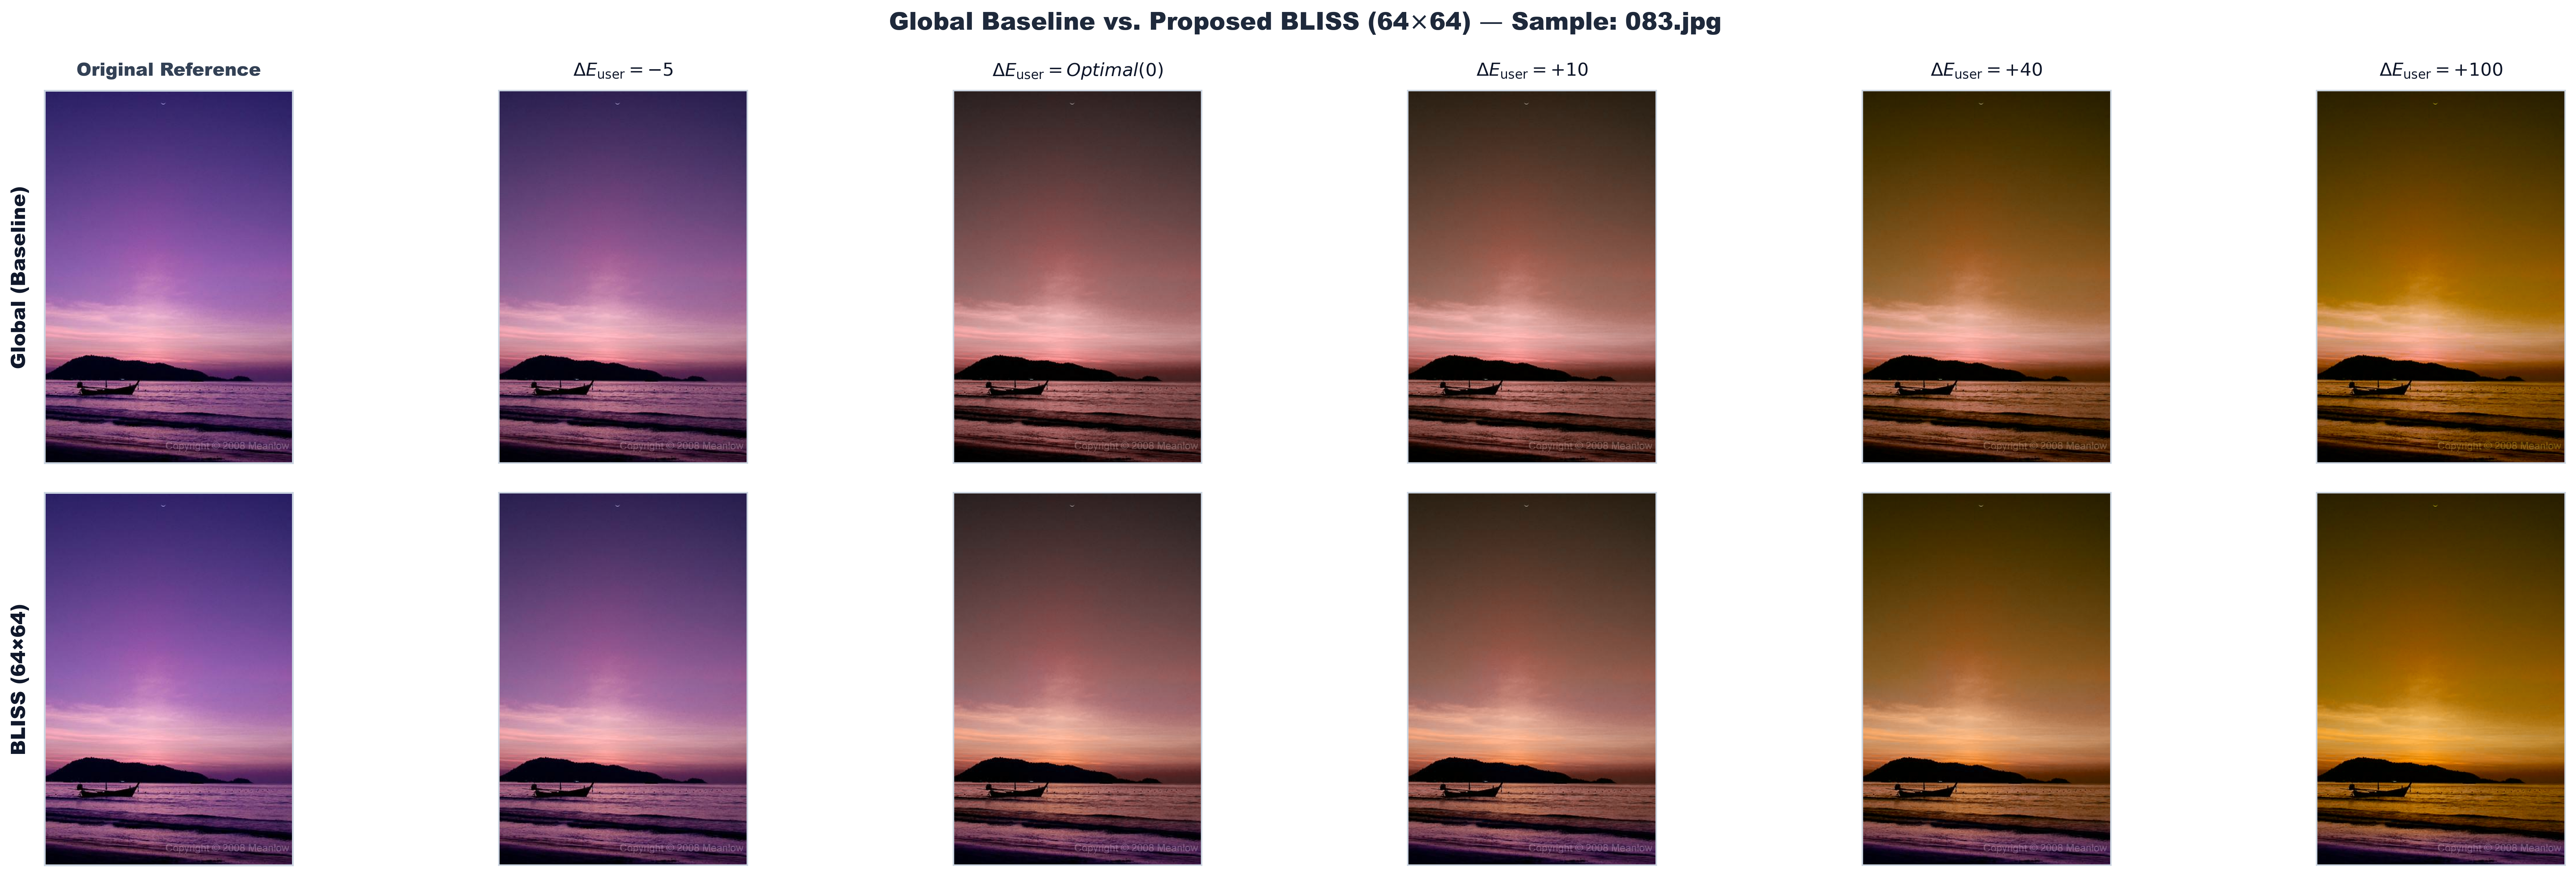

In [5]:
# Cell 4: Two-Row Visual Comparison (Global vs. BLISS) & Single-Image Metrics Report
# Configuration for single-image inspection
SAMPLE_IMAGE_INDEX = 3  # Change index to inspect other images in DATASET_PATH
VIS_BLOCK_SIZE = 64      # Spatial grid resolution for BLISS
ASSETS_DIR = os.path.join(PROJECT_ROOT, "assets")
os.makedirs(ASSETS_DIR, exist_ok=True)

# Load target sample image
image_files = [f for f in os.listdir(DATASET_PATH) if f.endswith(('.png', '.jpg', '.jpeg'))]
sample_img_name = image_files[SAMPLE_IMAGE_INDEX]
sample_img_path = os.path.join(DATASET_PATH, sample_img_name)
orig_sample = load_image_rgb(sample_img_path)

sorted_delta_es = sorted(DELTA_E_USERS)
global_images = {}
bliss_images = {}
single_img_records = []

# Run both methods across all Delta E thresholds and log per-image metrics
for de in sorted_delta_es:
    # 1. Global (Paper Baseline)
    t0 = time.perf_counter()
    img_glob, _, _ = apply_base_filter(orig_sample, de)
    t_glob = time.perf_counter() - t0
    global_images[de] = img_glob

    rec_glob = {"Method": "Global", "Delta_E_User": de}
    rec_glob.update(evaluate_metrics(orig_sample, img_glob, t_glob))
    single_img_records.append(rec_glob)

    # 2. BLISS (Proposed)
    t0 = time.perf_counter()
    img_bliss = apply_smooth_local_filter(orig_sample, de, VIS_BLOCK_SIZE)
    t_bliss = time.perf_counter() - t0
    bliss_images[de] = img_bliss

    rec_bliss = {"Method": "BLISS", "Delta_E_User": de}
    rec_bliss.update(evaluate_metrics(orig_sample, img_bliss, t_bliss))
    single_img_records.append(rec_bliss)

# ==============================================================================
# Part A: Two-Row Visual Comparison Plot (Row 1: Global | Row 2: BLISS)
# ==============================================================================
n_cols = len(sorted_delta_es) + 1
fig, axes = plt.subplots(2, n_cols, figsize=(4.2 * n_cols, 8.2))

fig.suptitle(
    rf"Global Baseline vs. Proposed BLISS ({VIS_BLOCK_SIZE}$\times${VIS_BLOCK_SIZE}) — Sample: {sample_img_name}",
    fontsize=16,
    fontweight="bold",
    color="#1e293b",
)

row_configs = [
    ("Global (Baseline)", global_images),
    (f"BLISS ({VIS_BLOCK_SIZE}×{VIS_BLOCK_SIZE})", bliss_images),
]

for row_idx, (row_label, img_dict) in enumerate(row_configs):
    # Column 0: Original Reference Image for direct horizontal comparison
    ax_orig = axes[row_idx, 0]
    ax_orig.imshow(orig_sample)
    ax_orig.set_ylabel(row_label, fontsize=13, fontweight="bold", color="#0f172a", labelpad=10)
    if row_idx == 0:
        ax_orig.set_title("Original Reference", fontsize=12, fontweight="bold", pad=10, color="#334155")
    ax_orig.set_xticks([])
    ax_orig.set_yticks([])
    for spine in ax_orig.spines.values():
        spine.set_edgecolor("#cbd5e1")
        spine.set_linewidth(1.2)

    # Columns 1..N: Filtered outputs progressing across Delta E levels
    for col_idx, de in enumerate(sorted_delta_es, start=1):
        ax = axes[row_idx, col_idx]
        ax.imshow(img_dict[de])
        if row_idx == 0:
            mode_tag = "Optimal (0)" if de == 0 else (f"+{de}" if de > 0 else f"{de}")
            ax.set_title(rf"$\Delta E_{{\text{{user}}}} = {mode_tag}$", fontsize=12, fontweight="bold", pad=10, color="#0f172a")
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_edgecolor("#cbd5e1")
            spine.set_linewidth(1.0)

plt.tight_layout()
plt.subplots_adjust(top=0.89, wspace=0.06, hspace=0.08)

vis_comparison_path = os.path.join(ASSETS_DIR, "visual_comparison.png")
plt.savefig(vis_comparison_path, dpi=300, bbox_inches="tight")
plt.show()
# print(f"Two-row visual comparison saved to: {vis_comparison_path}")

# ==============================================================================
# Part B: Quantitative Metrics Table for This Specific Sample Image
# ==============================================================================
df_single = pd.DataFrame(single_img_records)

sample_metrics_cols = [
    "PSNR (Higher is Better)",
    "SSIM Overall (Higher is Better)",
    "GMSD (Lower is Better)",
    "Blue Absorption (Higher is Better)",
    "Volume Difference (Lower is Better)",
    "Delta E 2000 (Lower is Better)",
    "BRISQUE (Lower is Better)",
    "Time (s) (Lower is Better)",
]

for opt_metric in ["NIQE (Lower is Better)", "PIQE (Lower is Better)"]:
    if opt_metric in df_single.columns and df_single[opt_metric].abs().sum() > 0:
        sample_metrics_cols.insert(-1, opt_metric)

single_table_cols = {}
for de in sorted_delta_es:
    de_label = f"ΔE_user = {de}"
    row_g = df_single[(df_single["Delta_E_User"] == de) & (df_single["Method"] == "Global")]
    row_b = df_single[(df_single["Delta_E_User"] == de) & (df_single["Method"] == "BLISS")]
    single_table_cols[(de_label, "Global")] = row_g[sample_metrics_cols].iloc[0].values
    single_table_cols[(de_label, "BLISS")] = row_b[sample_metrics_cols].iloc[0].values

df_single_table = pd.DataFrame(single_table_cols, index=sample_metrics_cols)
df_single_table.columns = pd.MultiIndex.from_tuples(
    df_single_table.columns, names=["Threshold", "Method"]
)
df_single_table = df_single_table.round(4)

display(
    HTML(
        f"<h3 style='color: #1e293b; border-bottom: 2px solid #0284c7; padding-bottom: 6px; margin-top: 24px; font-family: sans-serif;'>"
        f"Quantitative Metrics for Sample Image: <code>{sample_img_name}</code> (BLISS Grid: {VIS_BLOCK_SIZE} &times; {VIS_BLOCK_SIZE})"
        f"</h3>"
    )
)

# Apply consistent pairwise sage-green styling
def _highlight_single_image_cells(row: pd.Series) -> list:
    styles = [""] * len(row)
    label = str(row.name)
    higher_better = True if "Higher is Better" in label else (False if "Lower is Better" in label else None)
    groups = list(row.index.get_level_values(0).unique())

    for g_idx, g_name in enumerate(groups):
        idxs = [i for i, col in enumerate(row.index) if col[0] == g_name]
        vals = [row.iloc[i] for i in idxs]
        best = (max(vals) if higher_better else min(vals)) if higher_better is not None else None

        for pos, i in enumerate(idxs):
            css = ["border-left: 3px solid #94a3b8;" if pos == 0 else "border-left: 1px solid #e2e8f0;"]
            if best is not None and np.isclose(row.iloc[i], best, atol=1e-6):
                css.append("font-weight: 700; background-color: #dcfce7; color: #166534;")
            else:
                bg = "#ffffff" if g_idx % 2 == 0 else "#f8fafc"
                css.append(f"background-color: {bg}; color: #334155;")
            styles[i] = " ".join(css)
    return styles

styled_single = (
    df_single_table.style.apply(_highlight_single_image_cells, axis=1)
    .format("{:.4f}")
    .set_table_styles(
        [
            {"selector": "", "props": [("border-collapse", "collapse"), ("font-size", "13px"), ("border", "1px solid #cbd5e1")]},
            {"selector": "th.col_heading.level0", "props": [("background-color", "#e0f2fe"), ("color", "#0f172a"), ("font-weight", "700"), ("text-align", "center"), ("border-left", "3px solid #94a3b8"), ("padding", "8px 14px")]},
            {"selector": "th.col_heading.level0:nth-of-type(even)", "props": [("background-color", "#f1f5f9")]},
            {"selector": "th.col_heading.level1", "props": [("background-color", "#f8fafc"), ("color", "#475569"), ("font-weight", "600"), ("text-align", "center"), ("border-bottom", "2px solid #94a3b8"), ("padding", "6px 14px")]},
            {"selector": "th.col_heading.level1:nth-child(even)", "props": [("border-left", "3px solid #94a3b8")]},
            {"selector": "th.col_heading.level1:nth-child(odd)", "props": [("border-left", "1px solid #e2e8f0")]},
            {"selector": "th.row_heading", "props": [("background-color", "#f8fafc"), ("color", "#1e293b"), ("font-weight", "600"), ("text-align", "left"), ("padding", "7px 14px"), ("white-space", "nowrap")]},
            {"selector": "th.blank, th.index_name", "props": [("background-color", "#f1f5f9"), ("color", "#475569"), ("padding", "7px 14px")]},
            {"selector": "td", "props": [("text-align", "center"), ("padding", "7px 14px"), ("border-bottom", "1px solid #e2e8f0")]},
        ]
    )
)

display(styled_single)

## 5. Multi-Grid Metric Trajectory Analysis across $\Delta E_{\text{user}}$

In this section, we visualize the performance trajectory of every evaluation metric as a function of user-defined filter intensity ($\Delta E_{\text{user}} \in \{-5, 0, +10, +40, +100\}$).

- **Horizontal Axis:** Progresses across increasing $\Delta E_{\text{user}}$ thresholds from conservative (`-5`) to maximum blue light attenuation (`+100`).
- **Curves:** Each solid curve represents **BLISS** at a specific spatial grid resolution (`4×4` through `256×256`), plotted alongside the dashed reference curve for the **Global (Baseline)** method.
- **Export:** All individual metric plots are saved at `300 DPI` inside `assets/metric_curves/`.

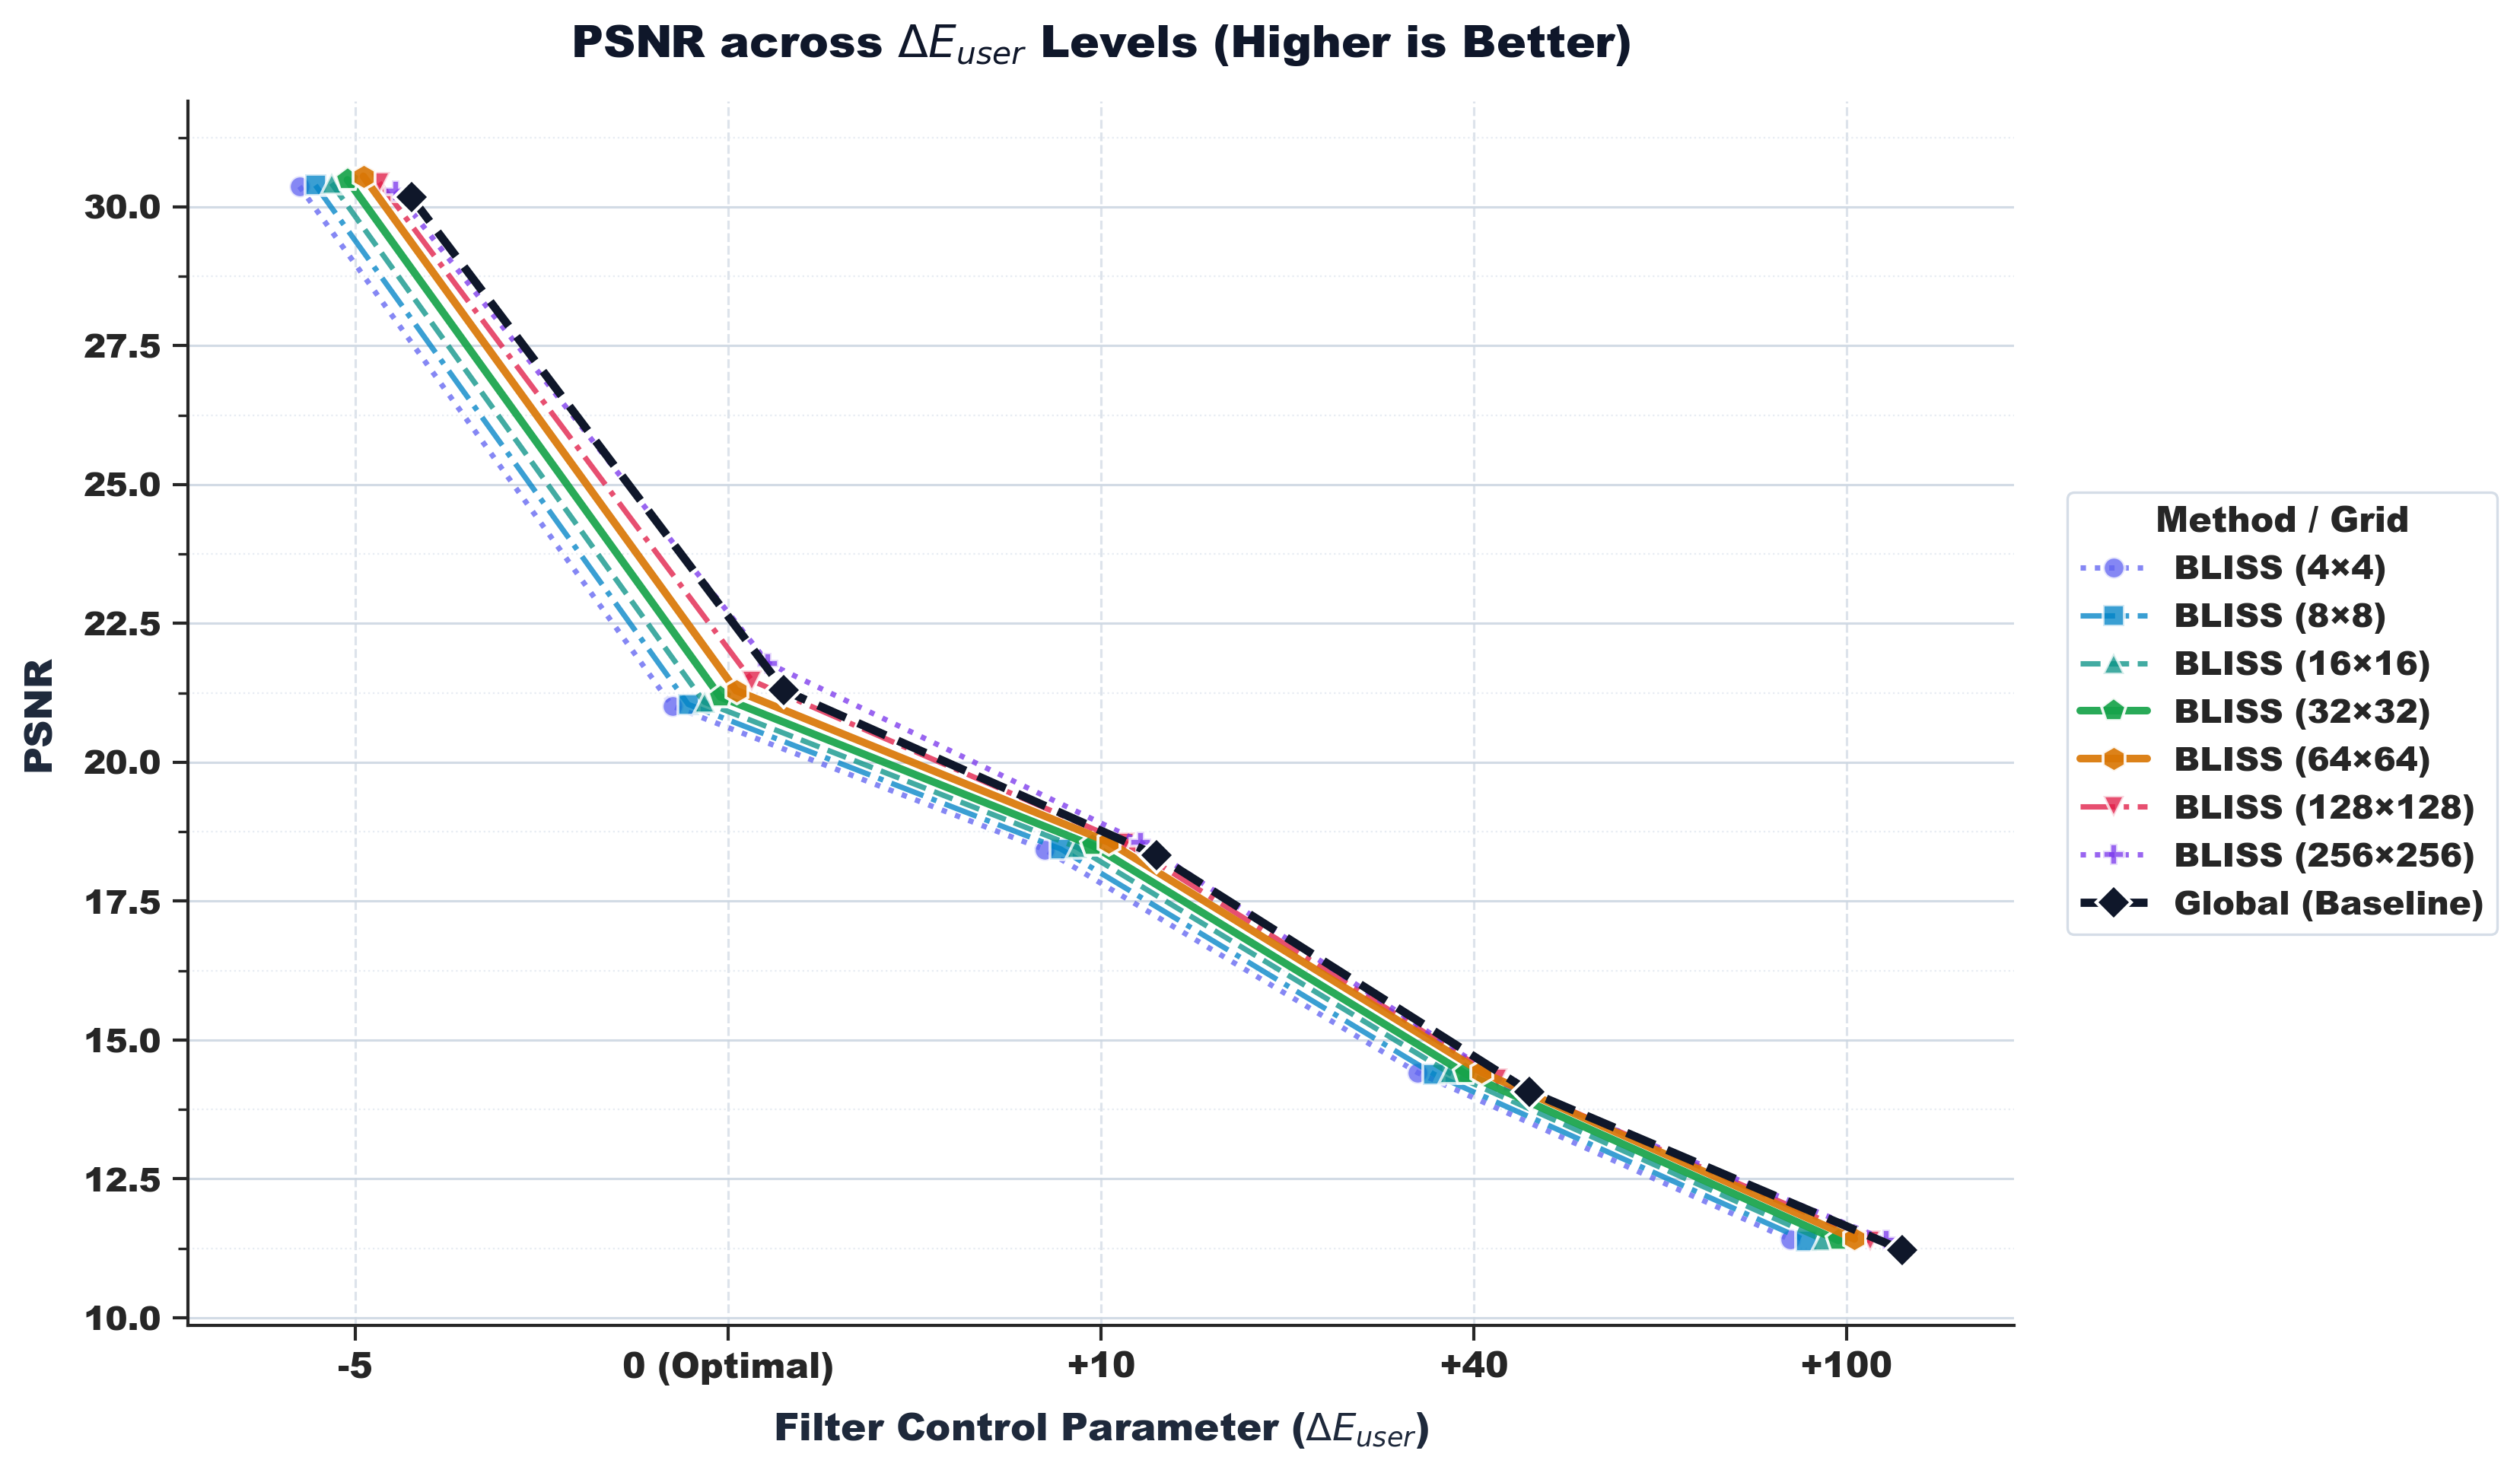

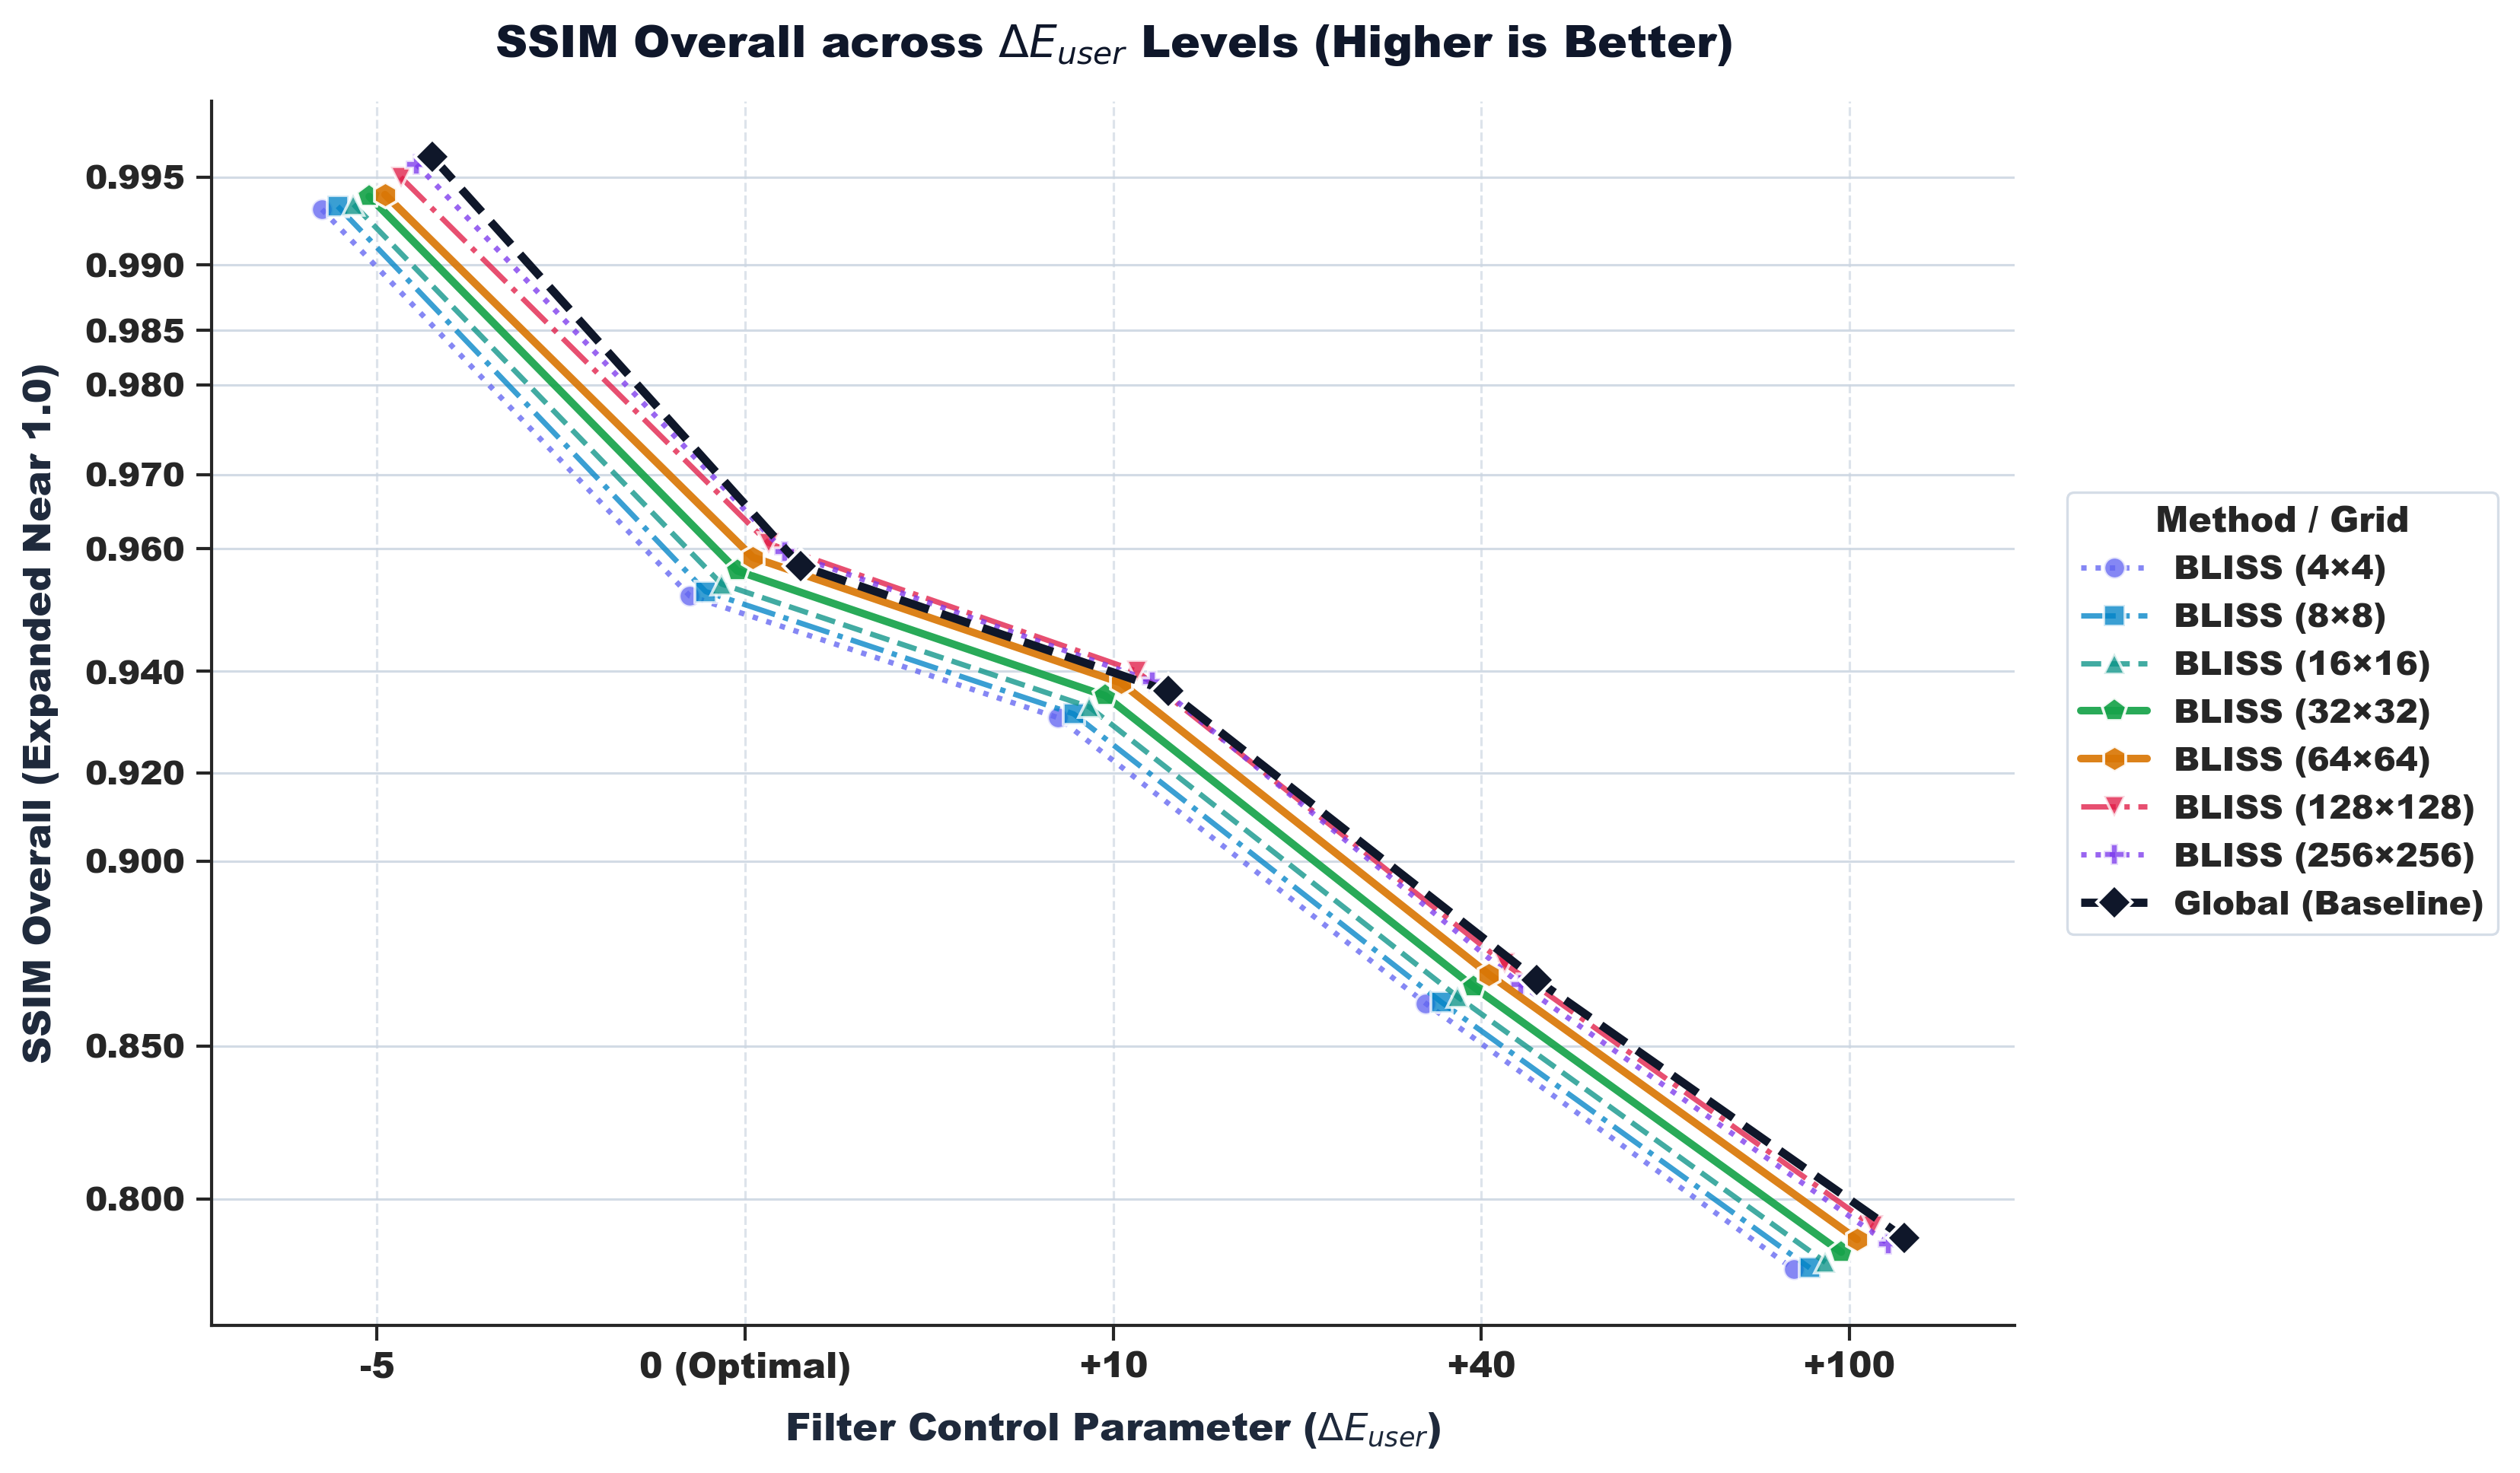

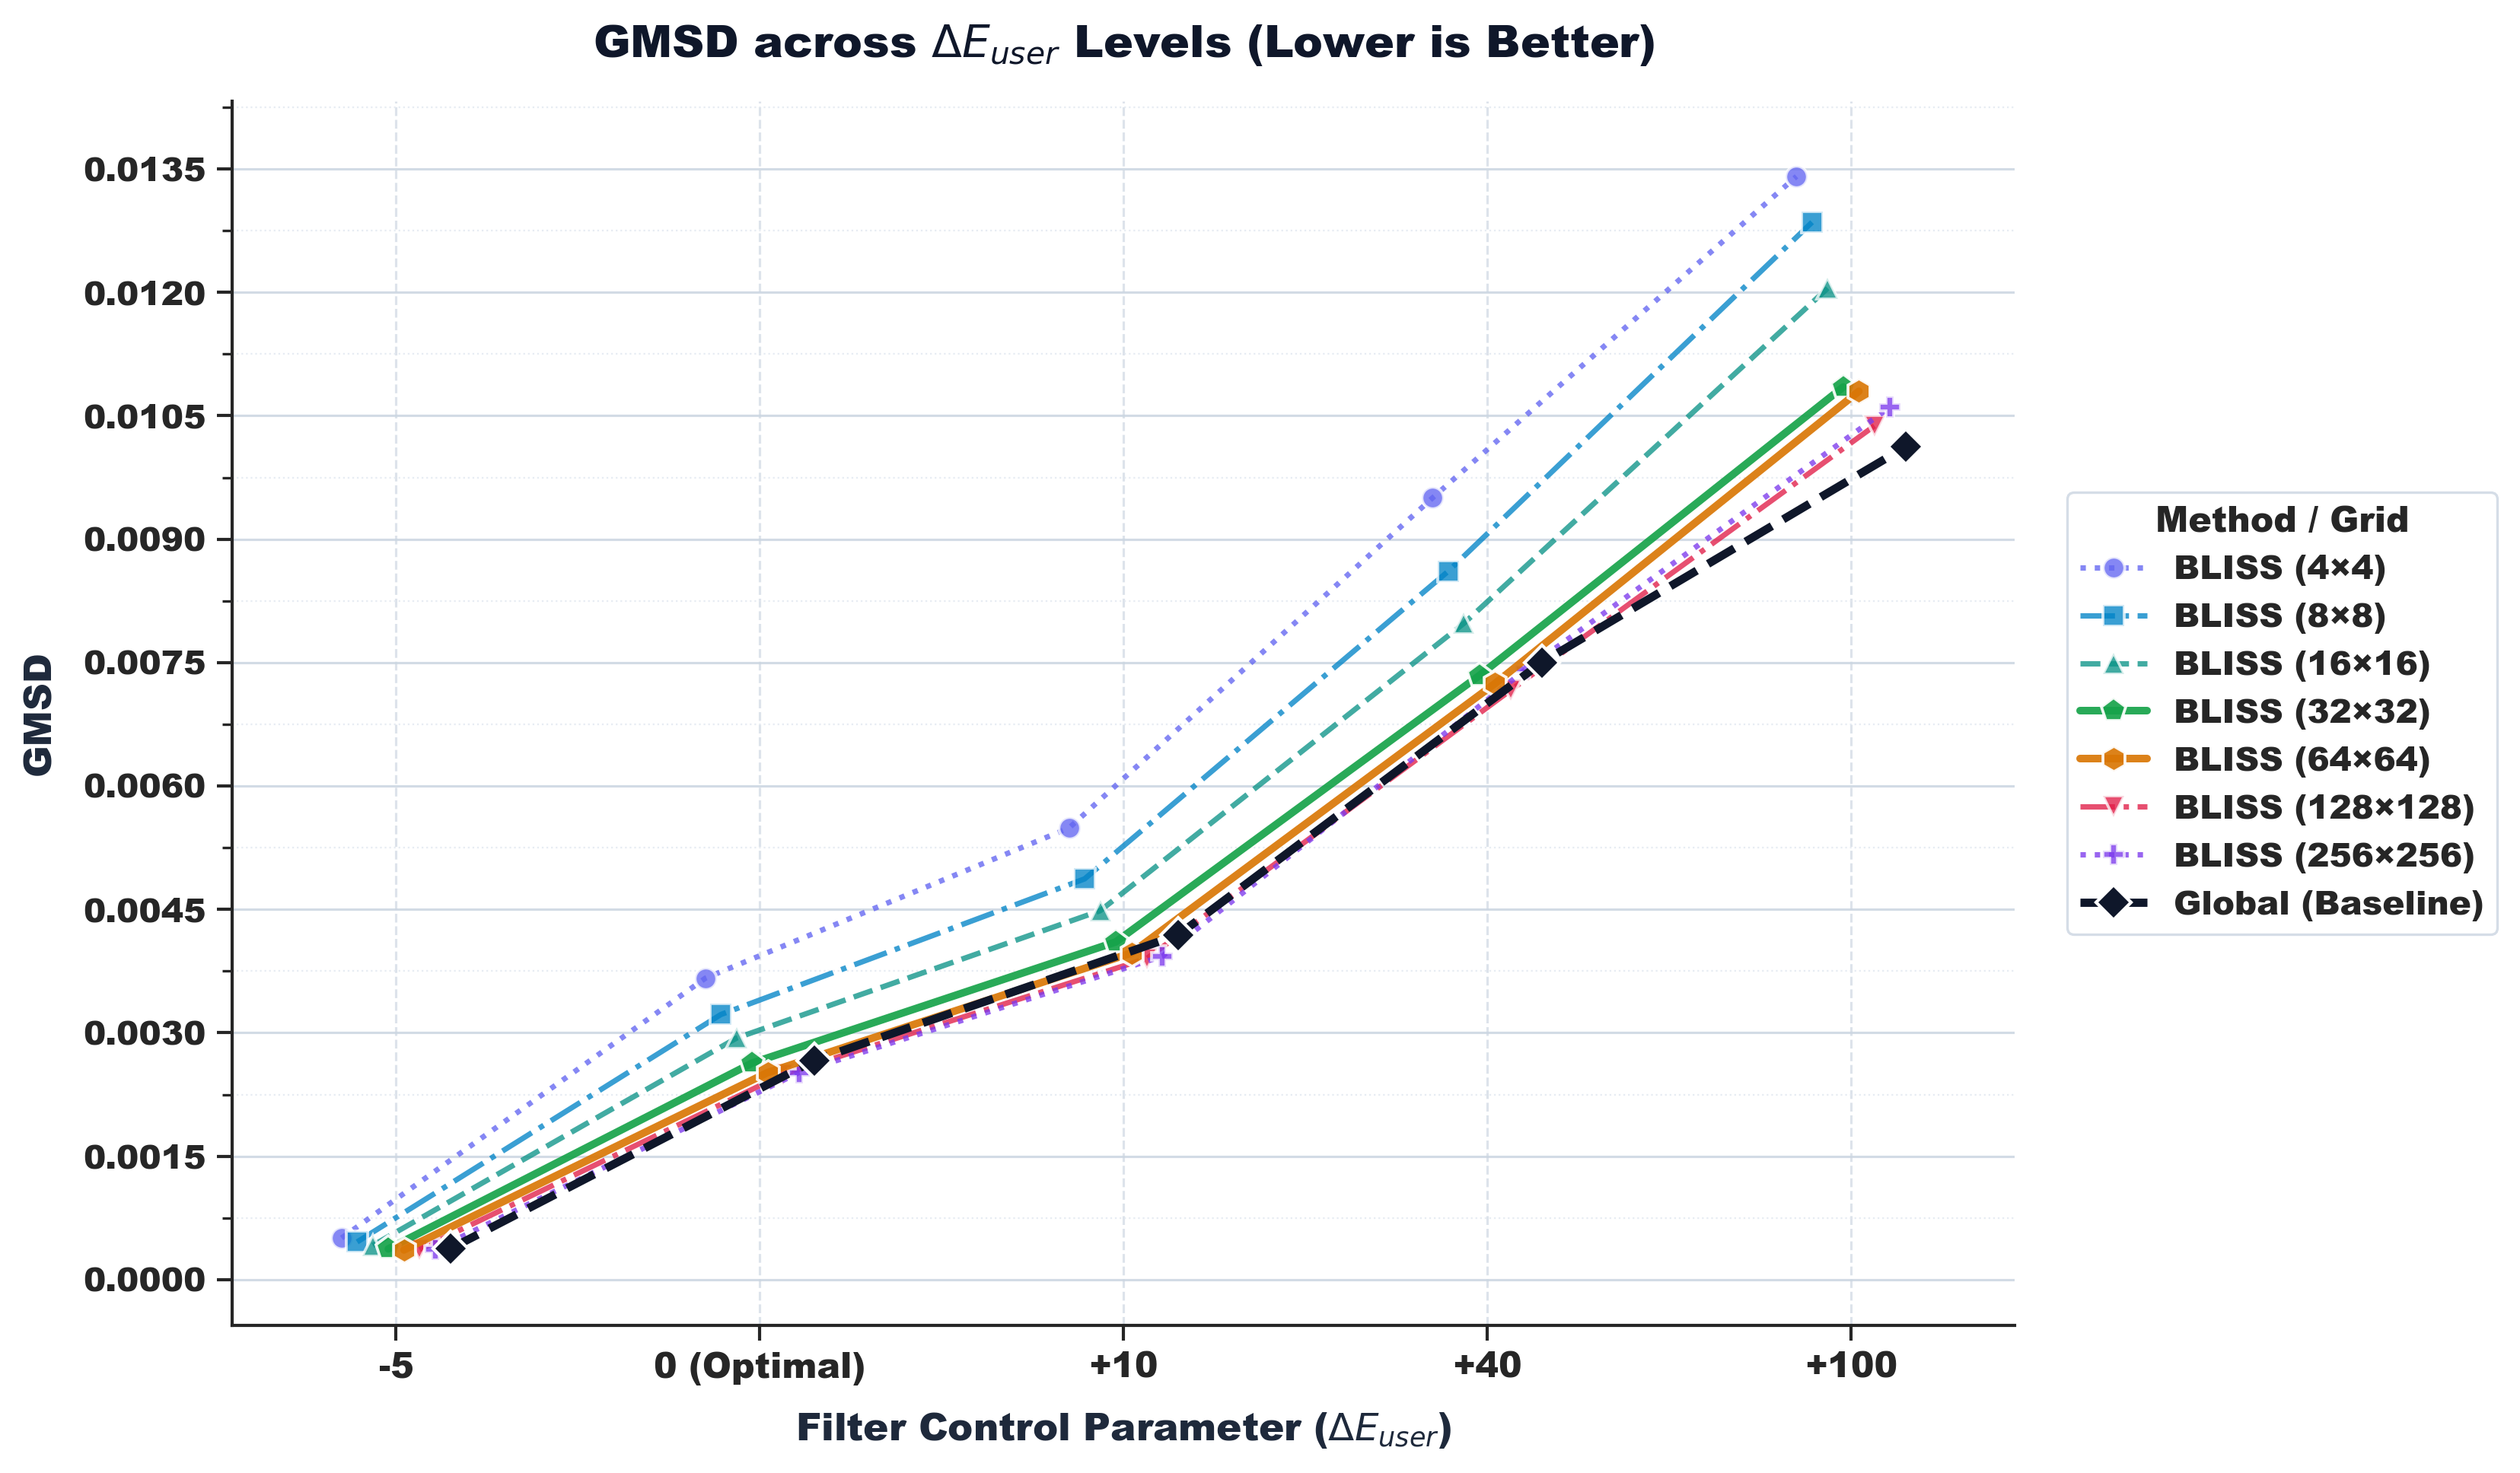

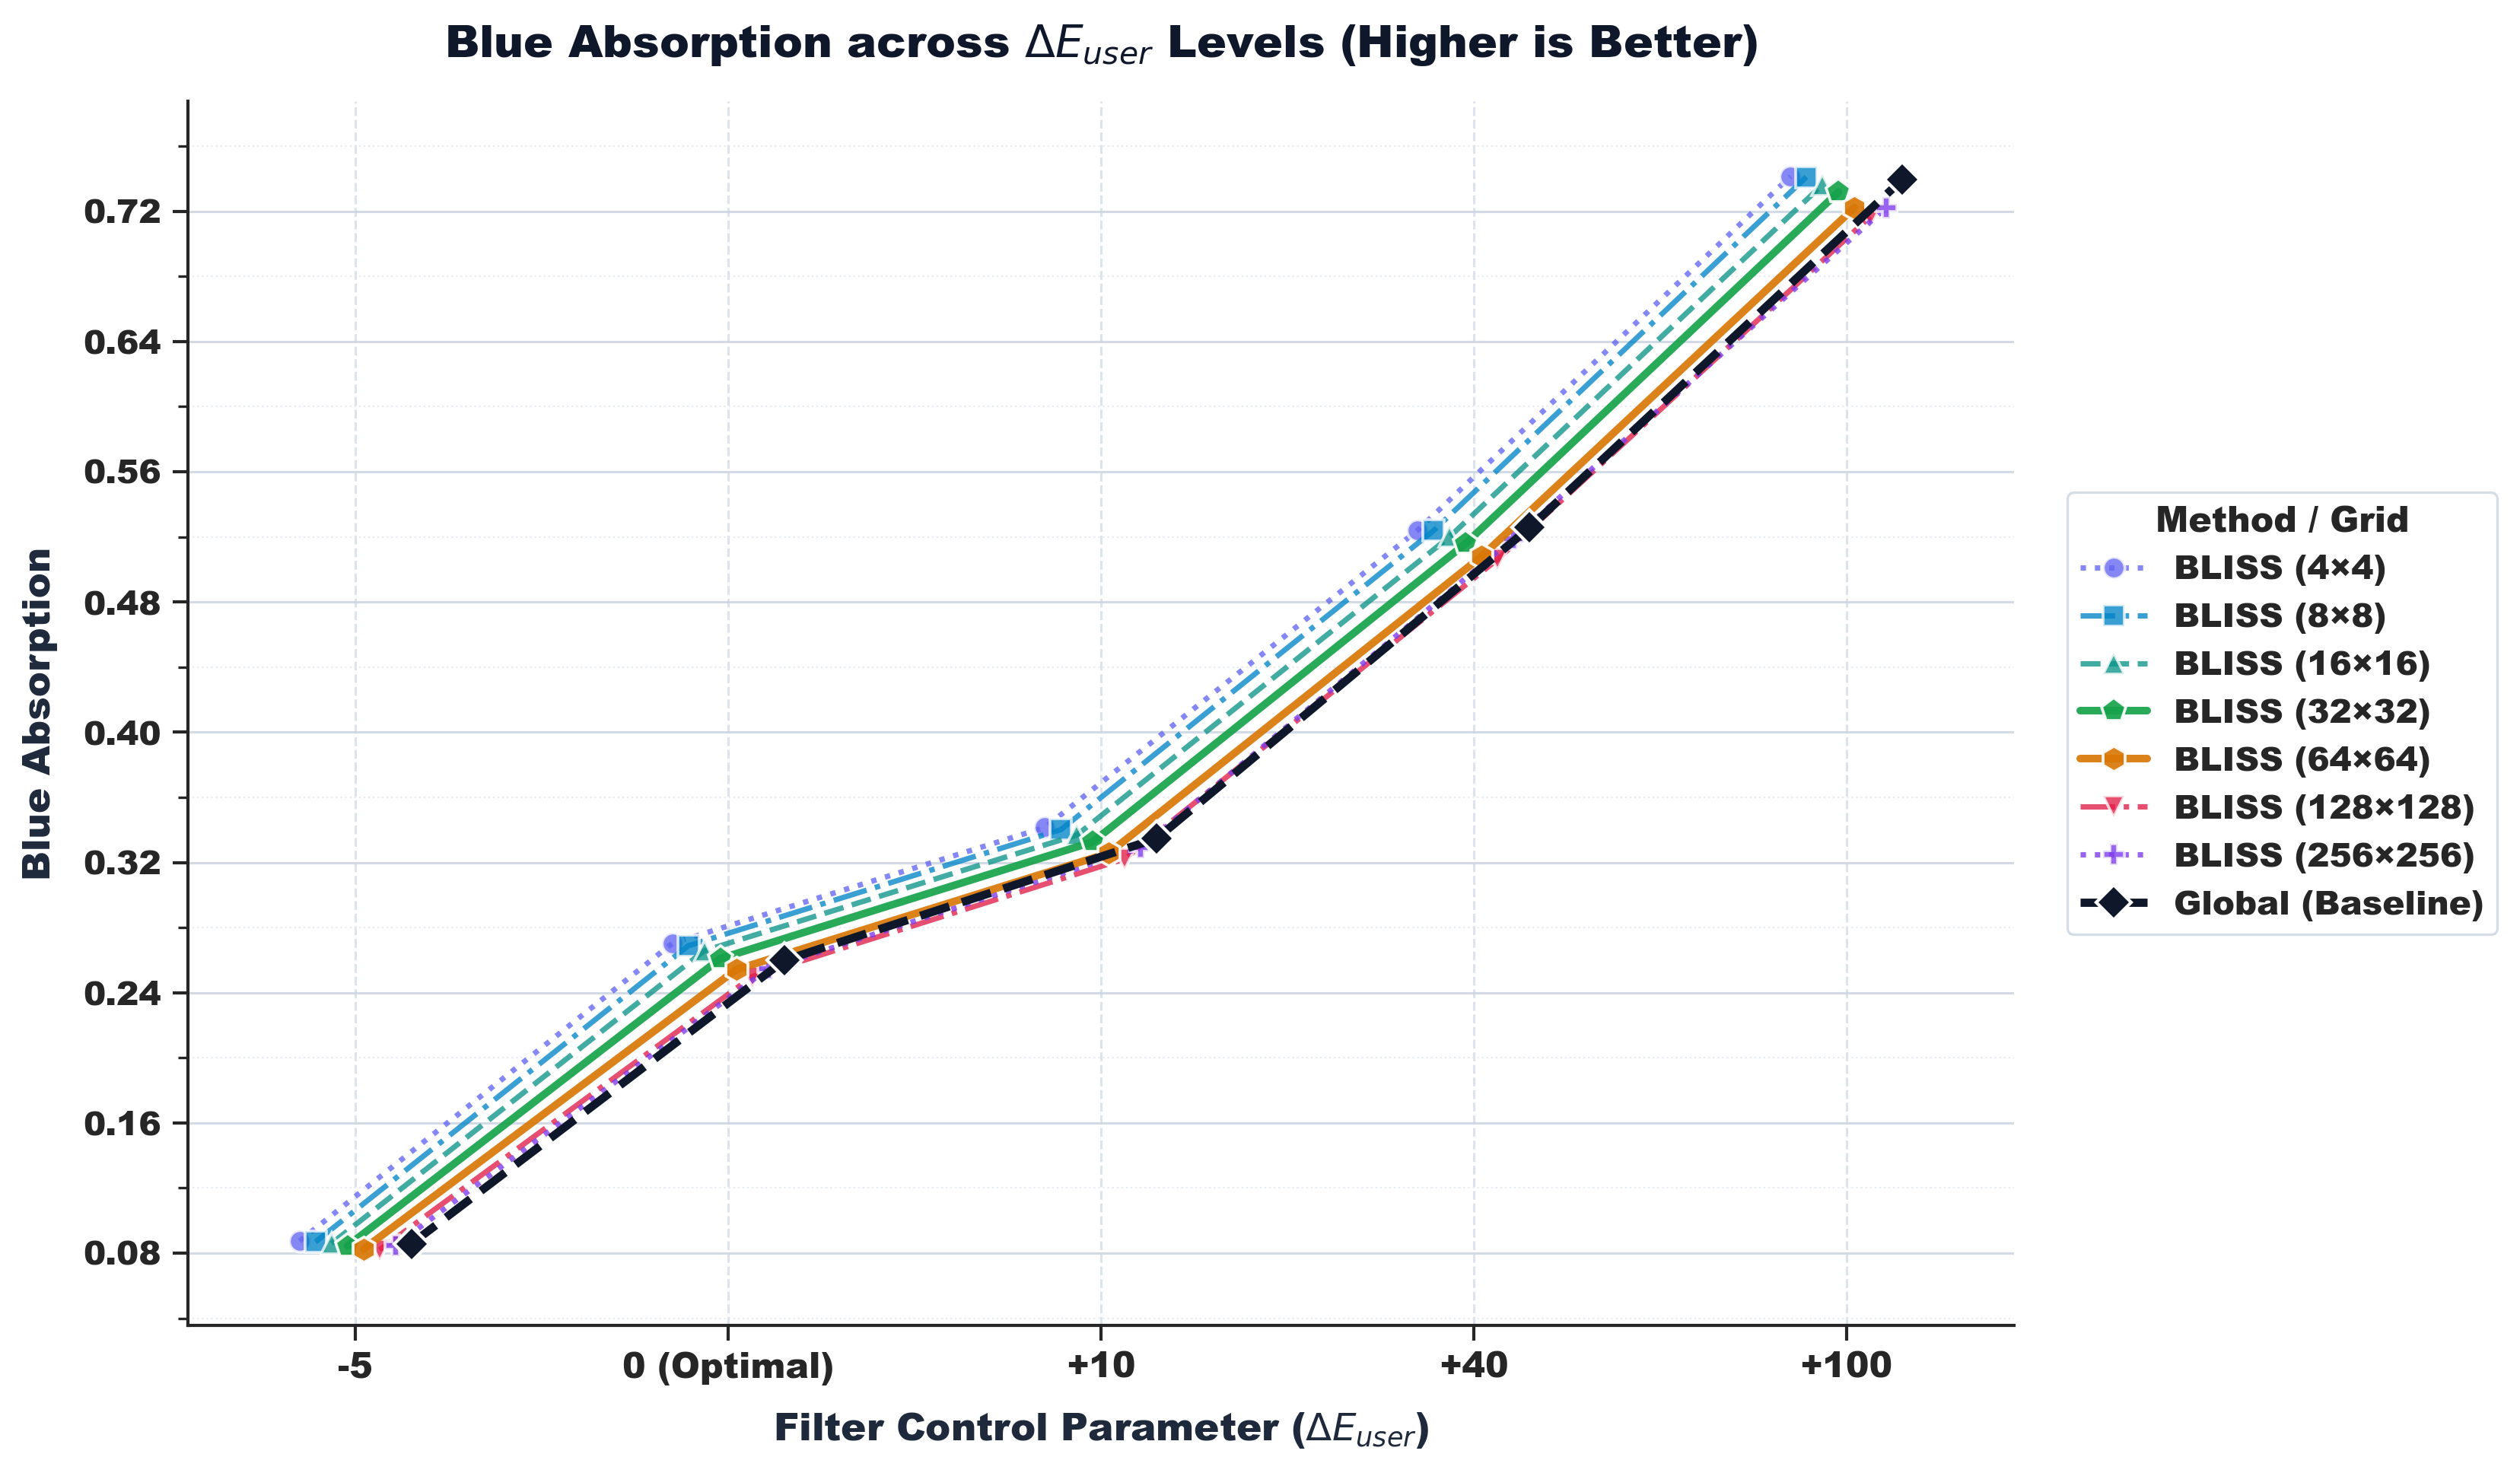

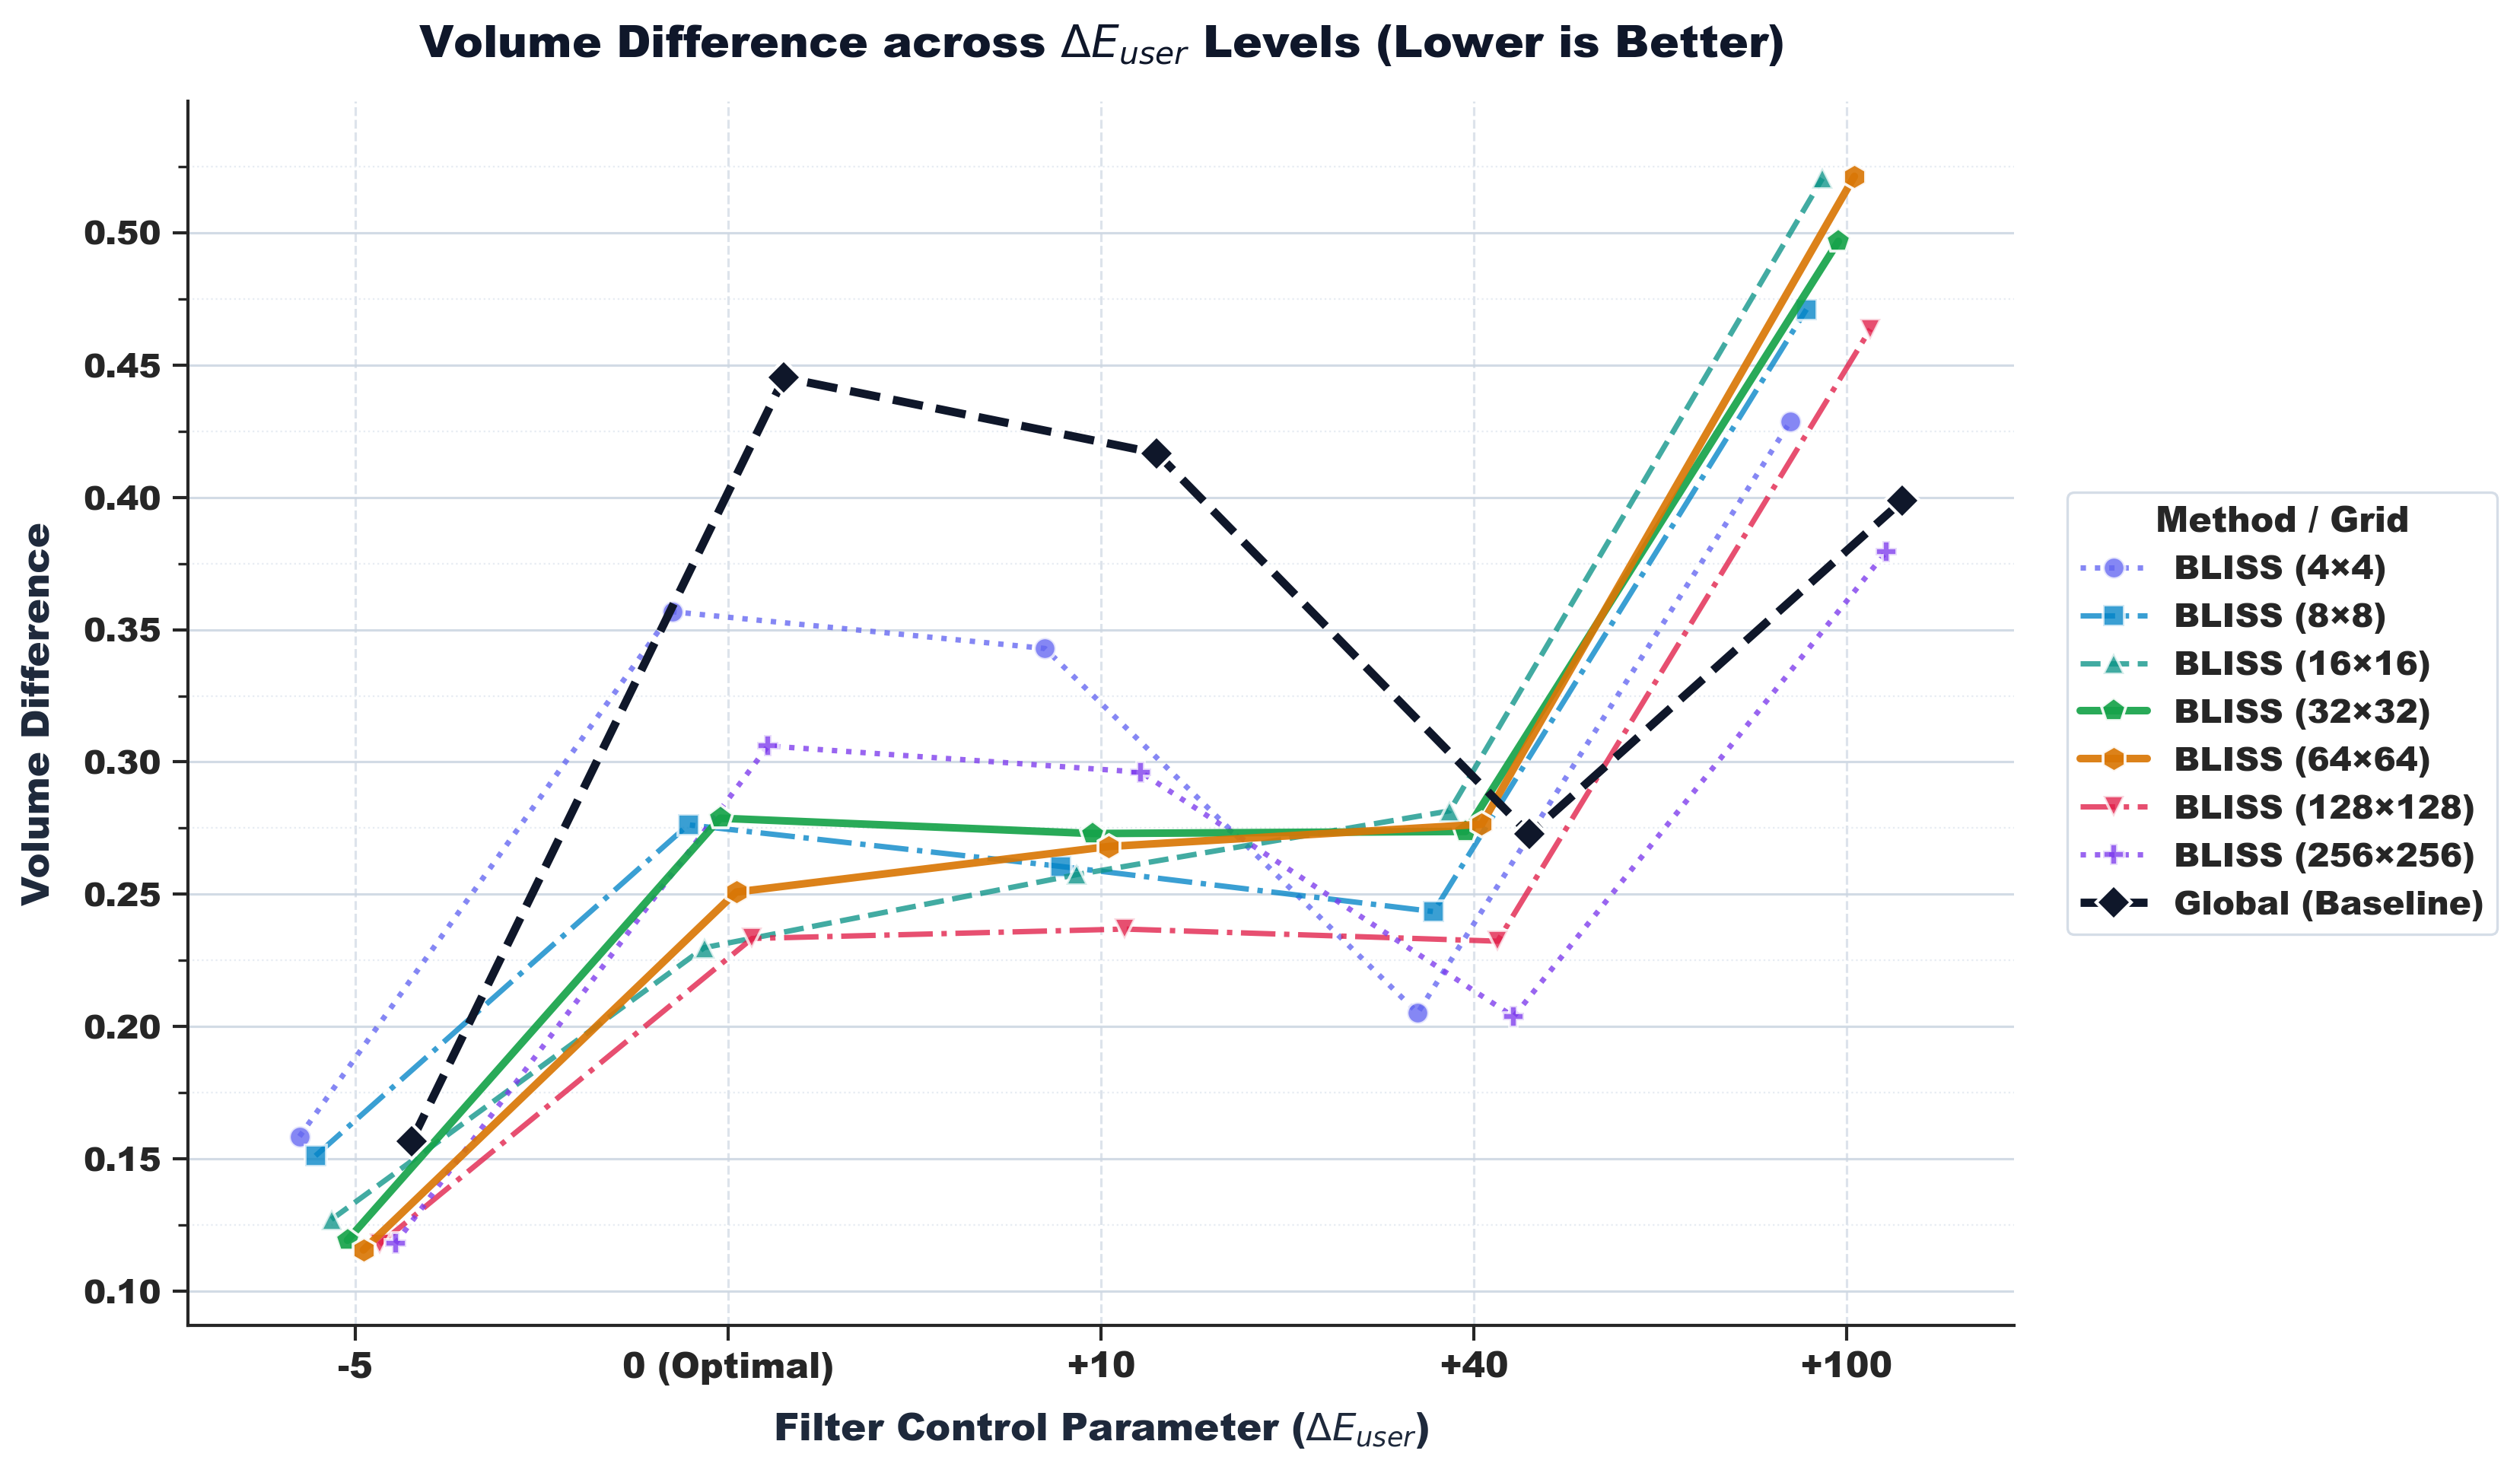

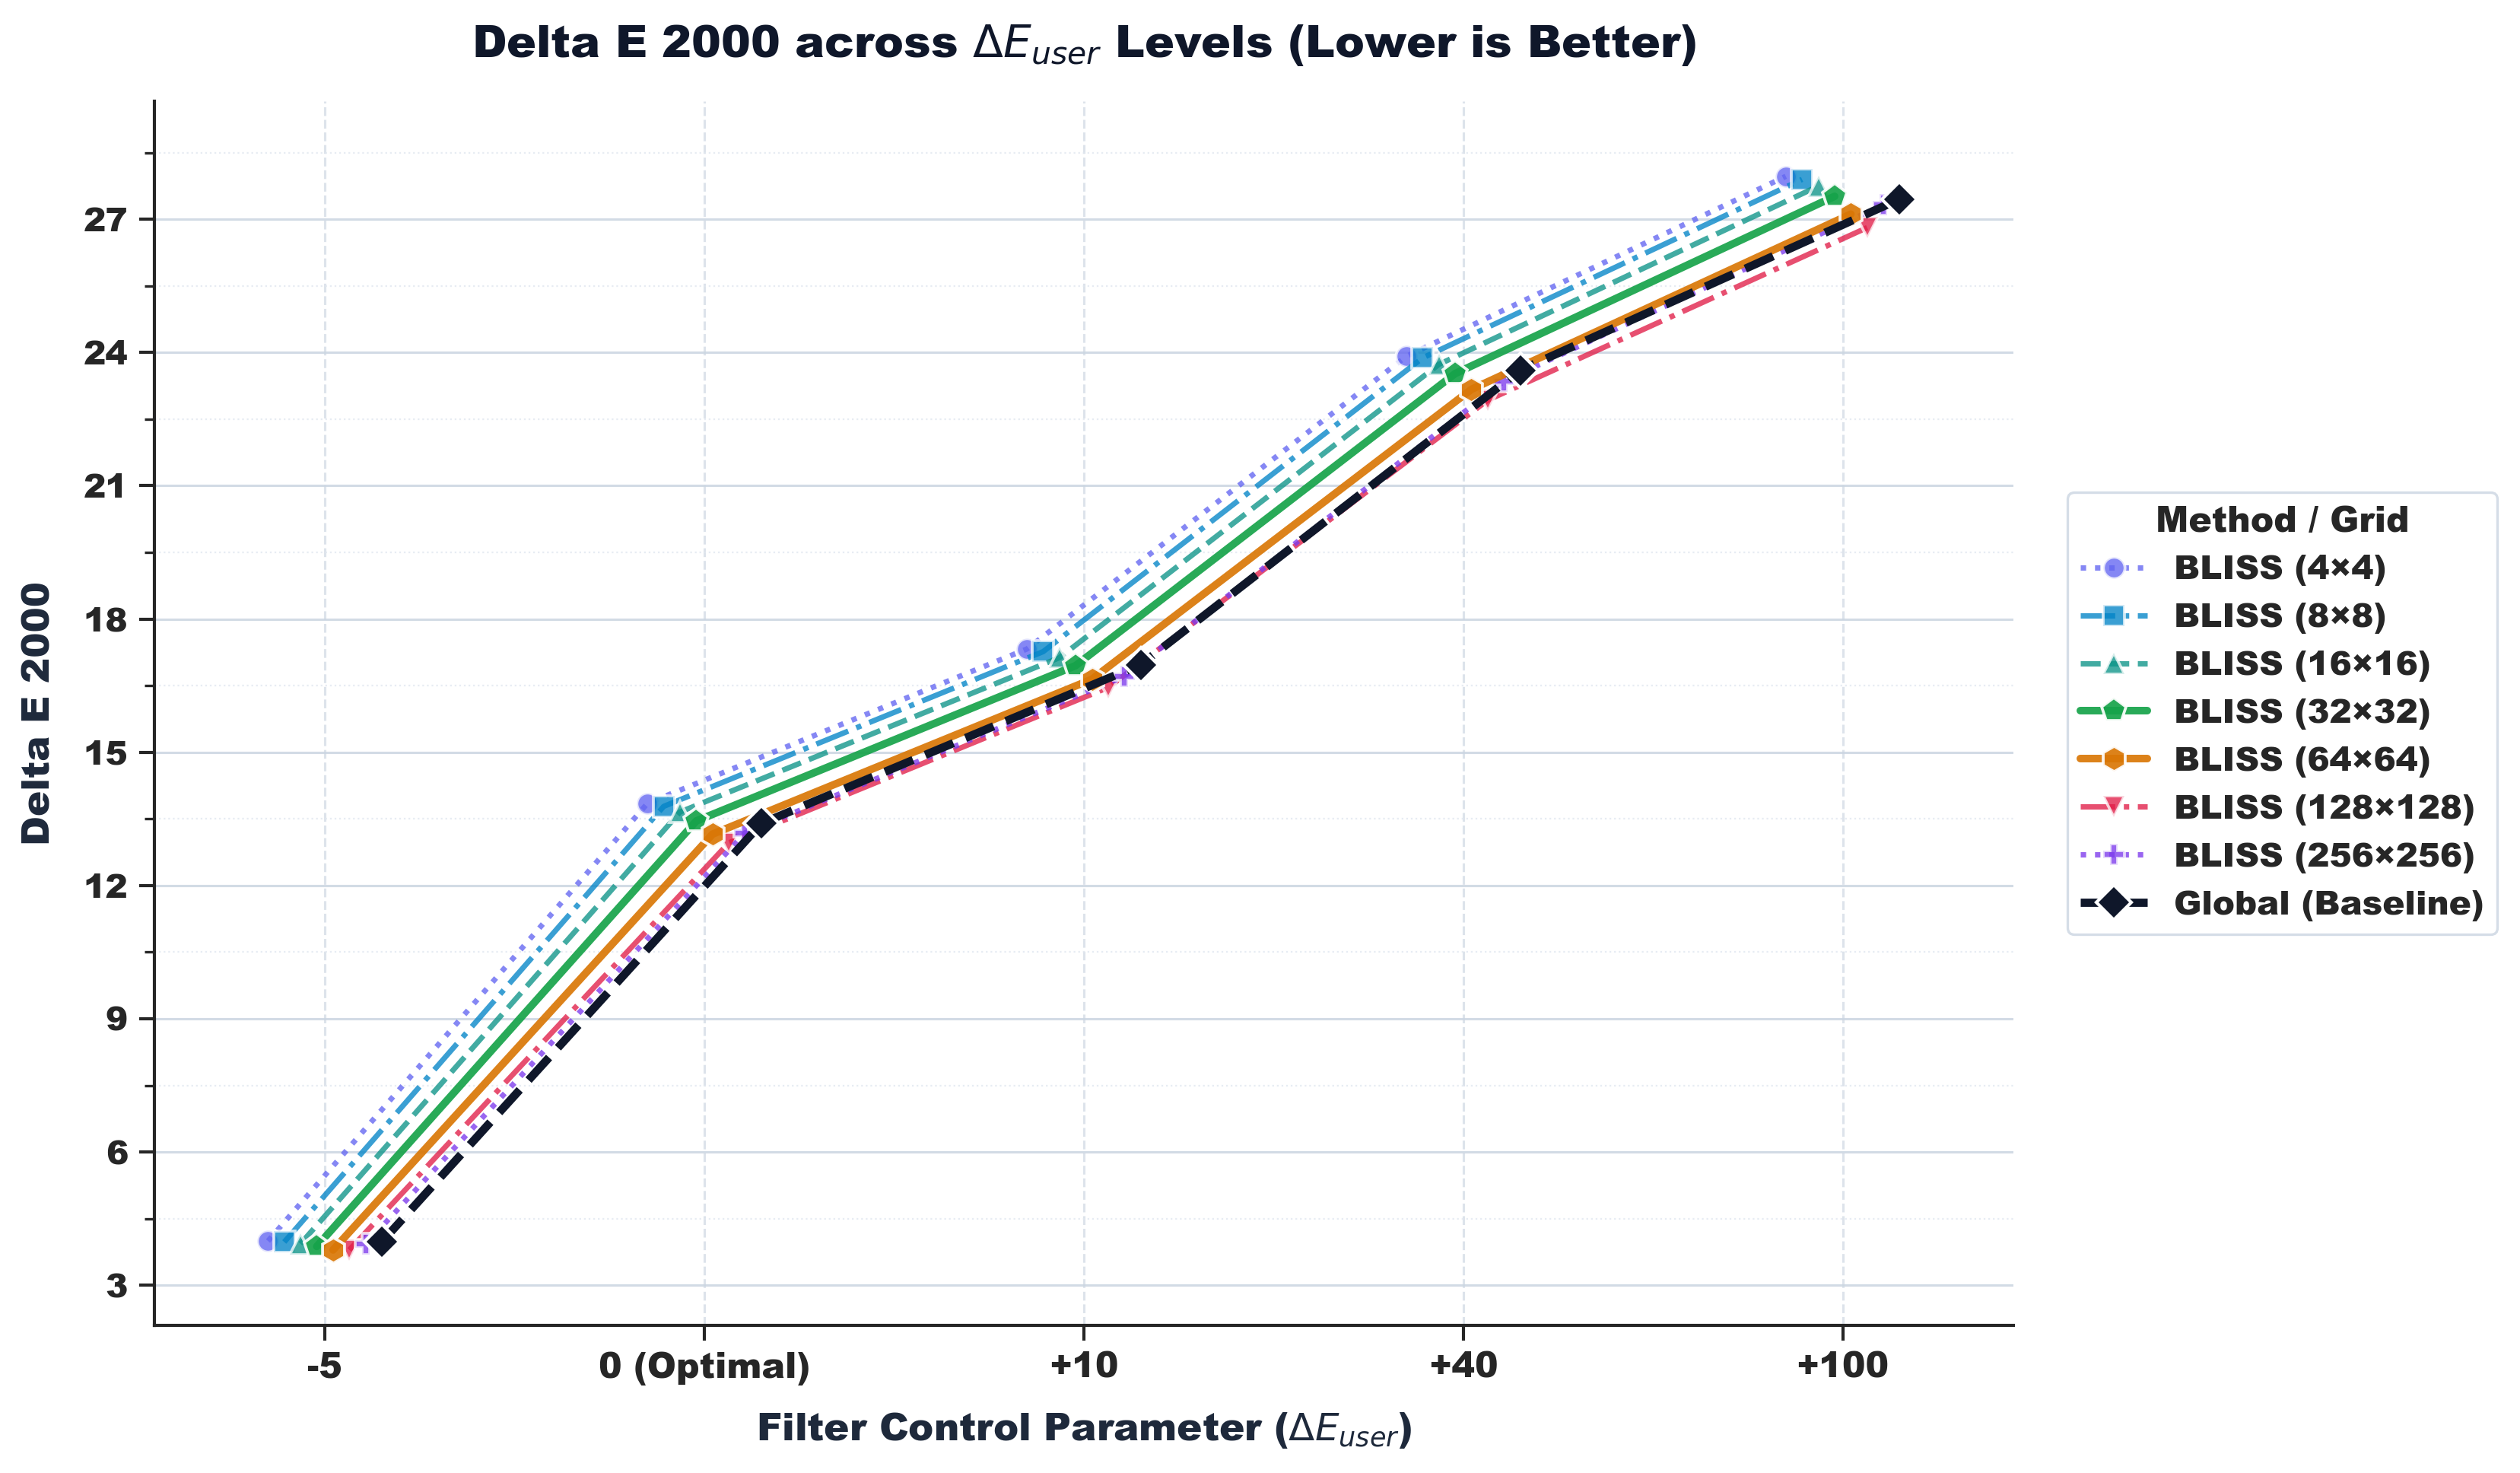

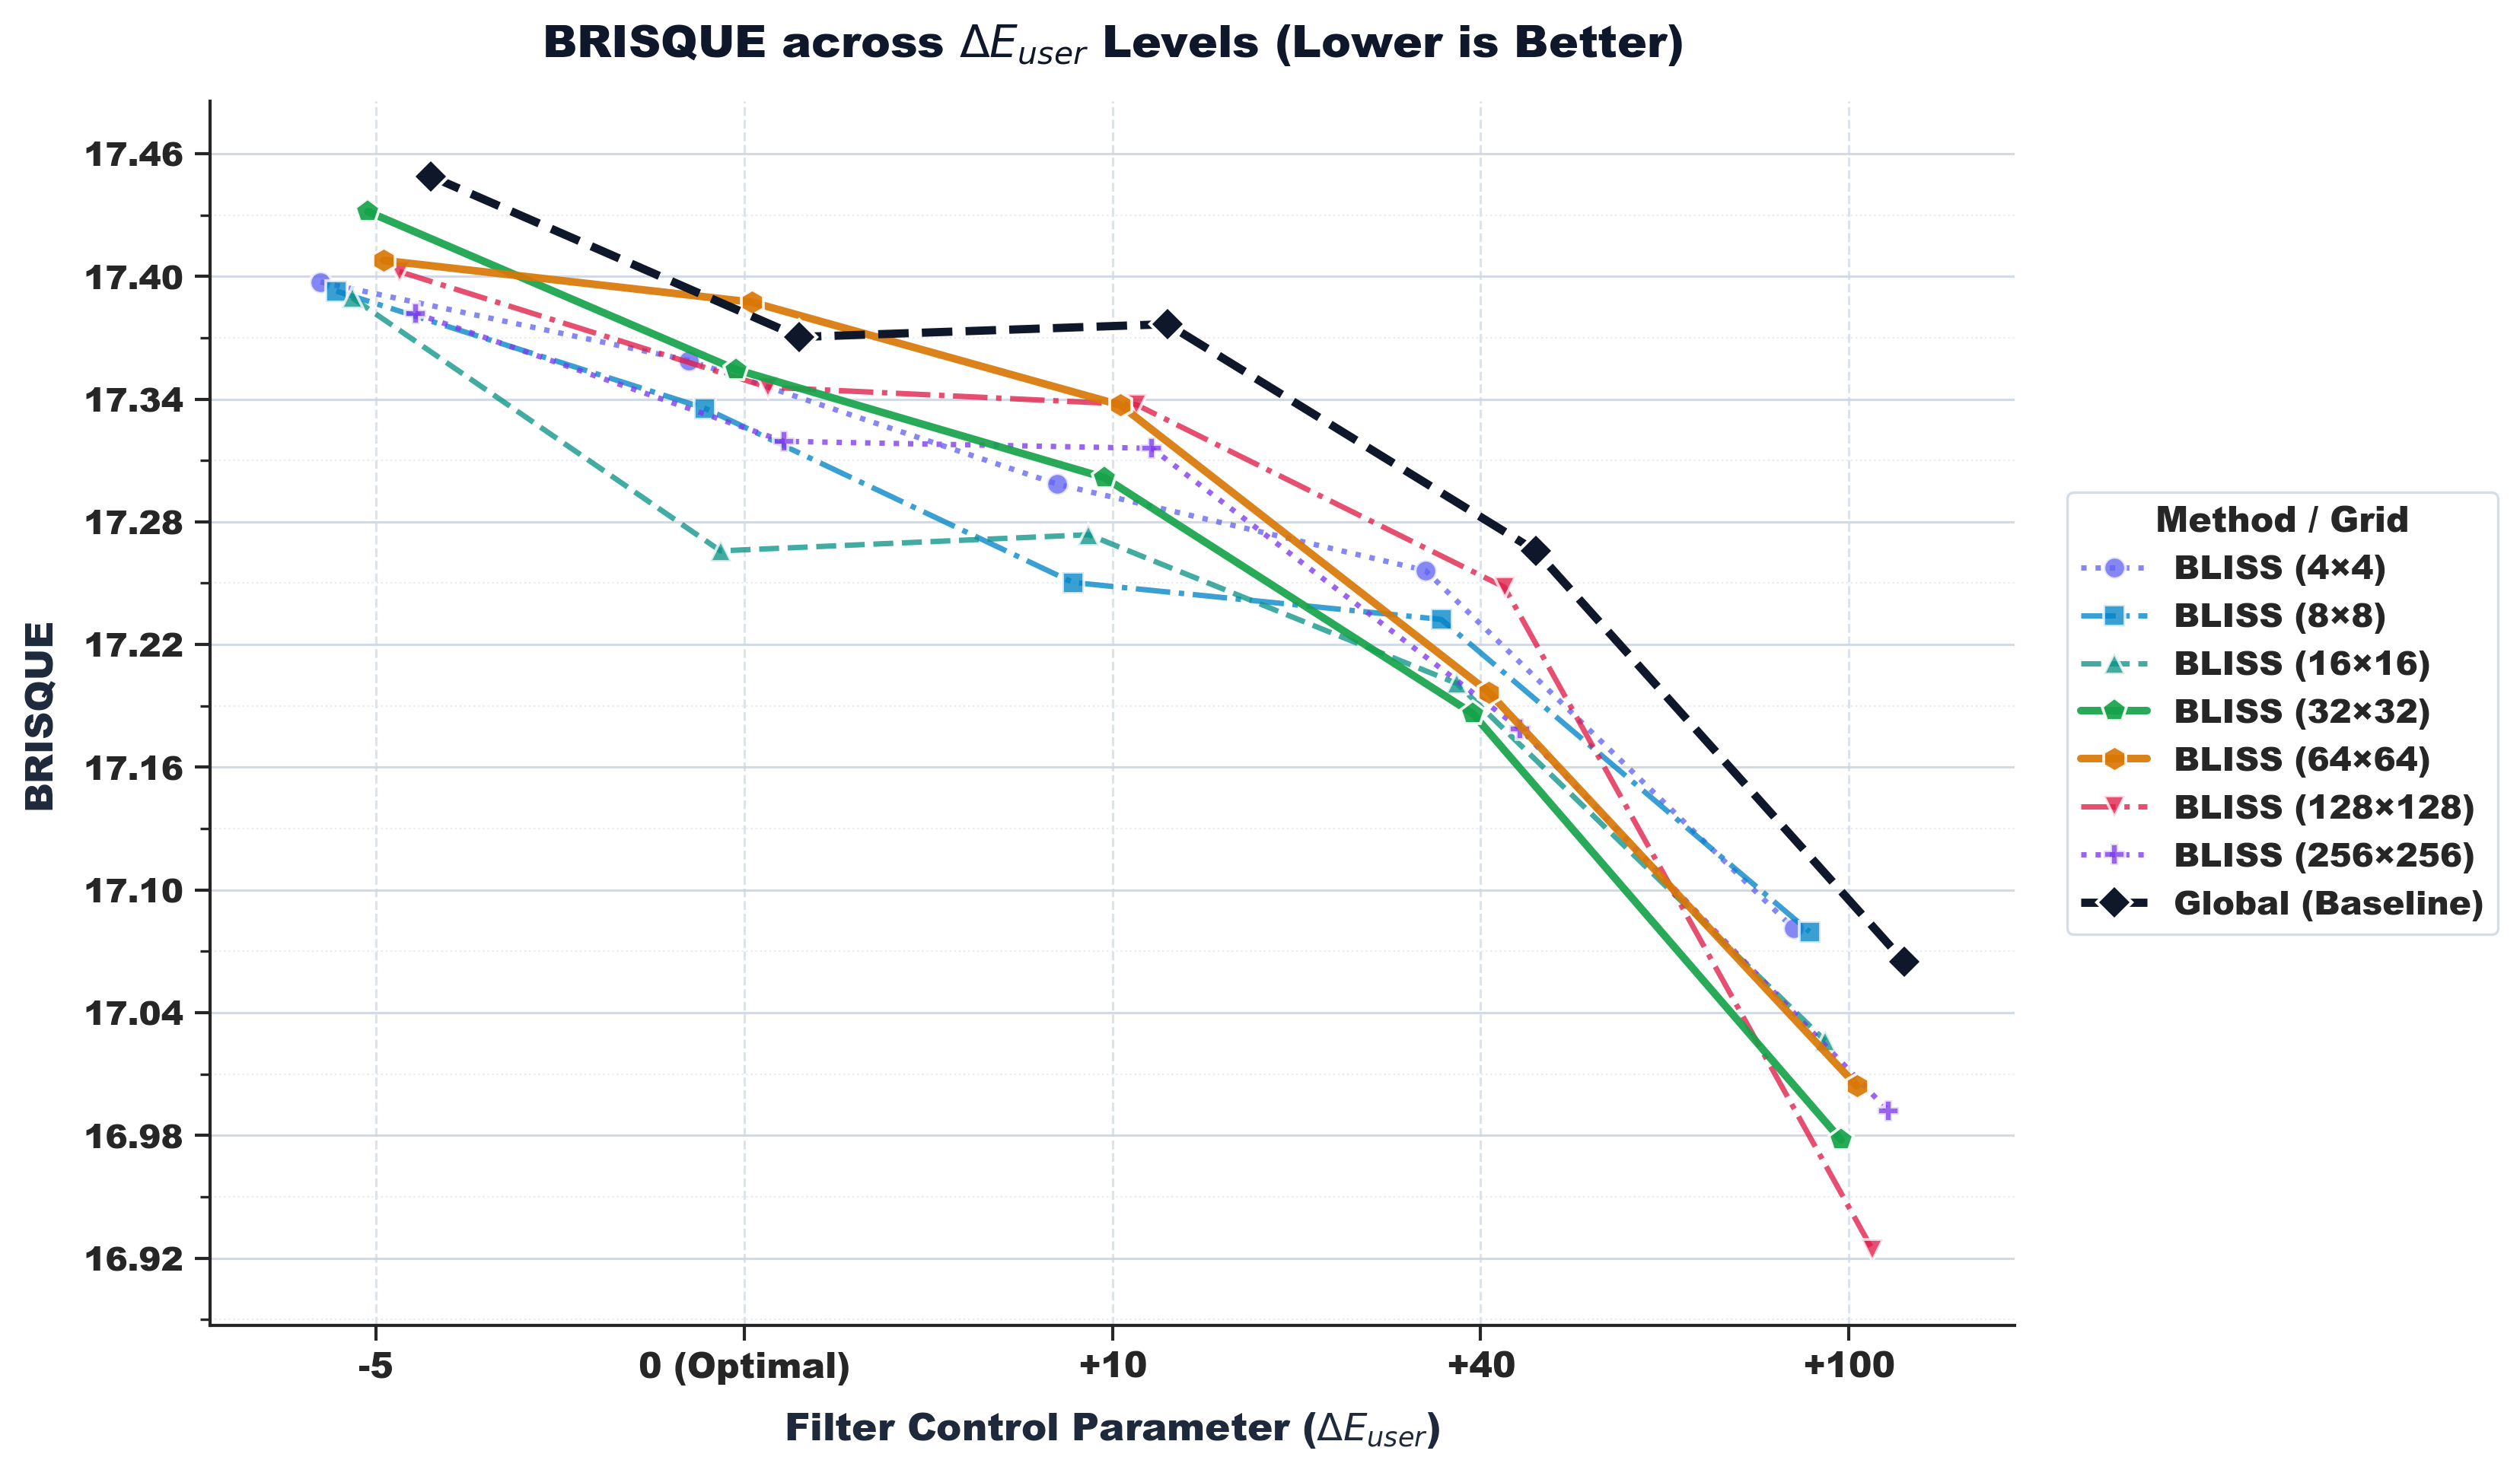

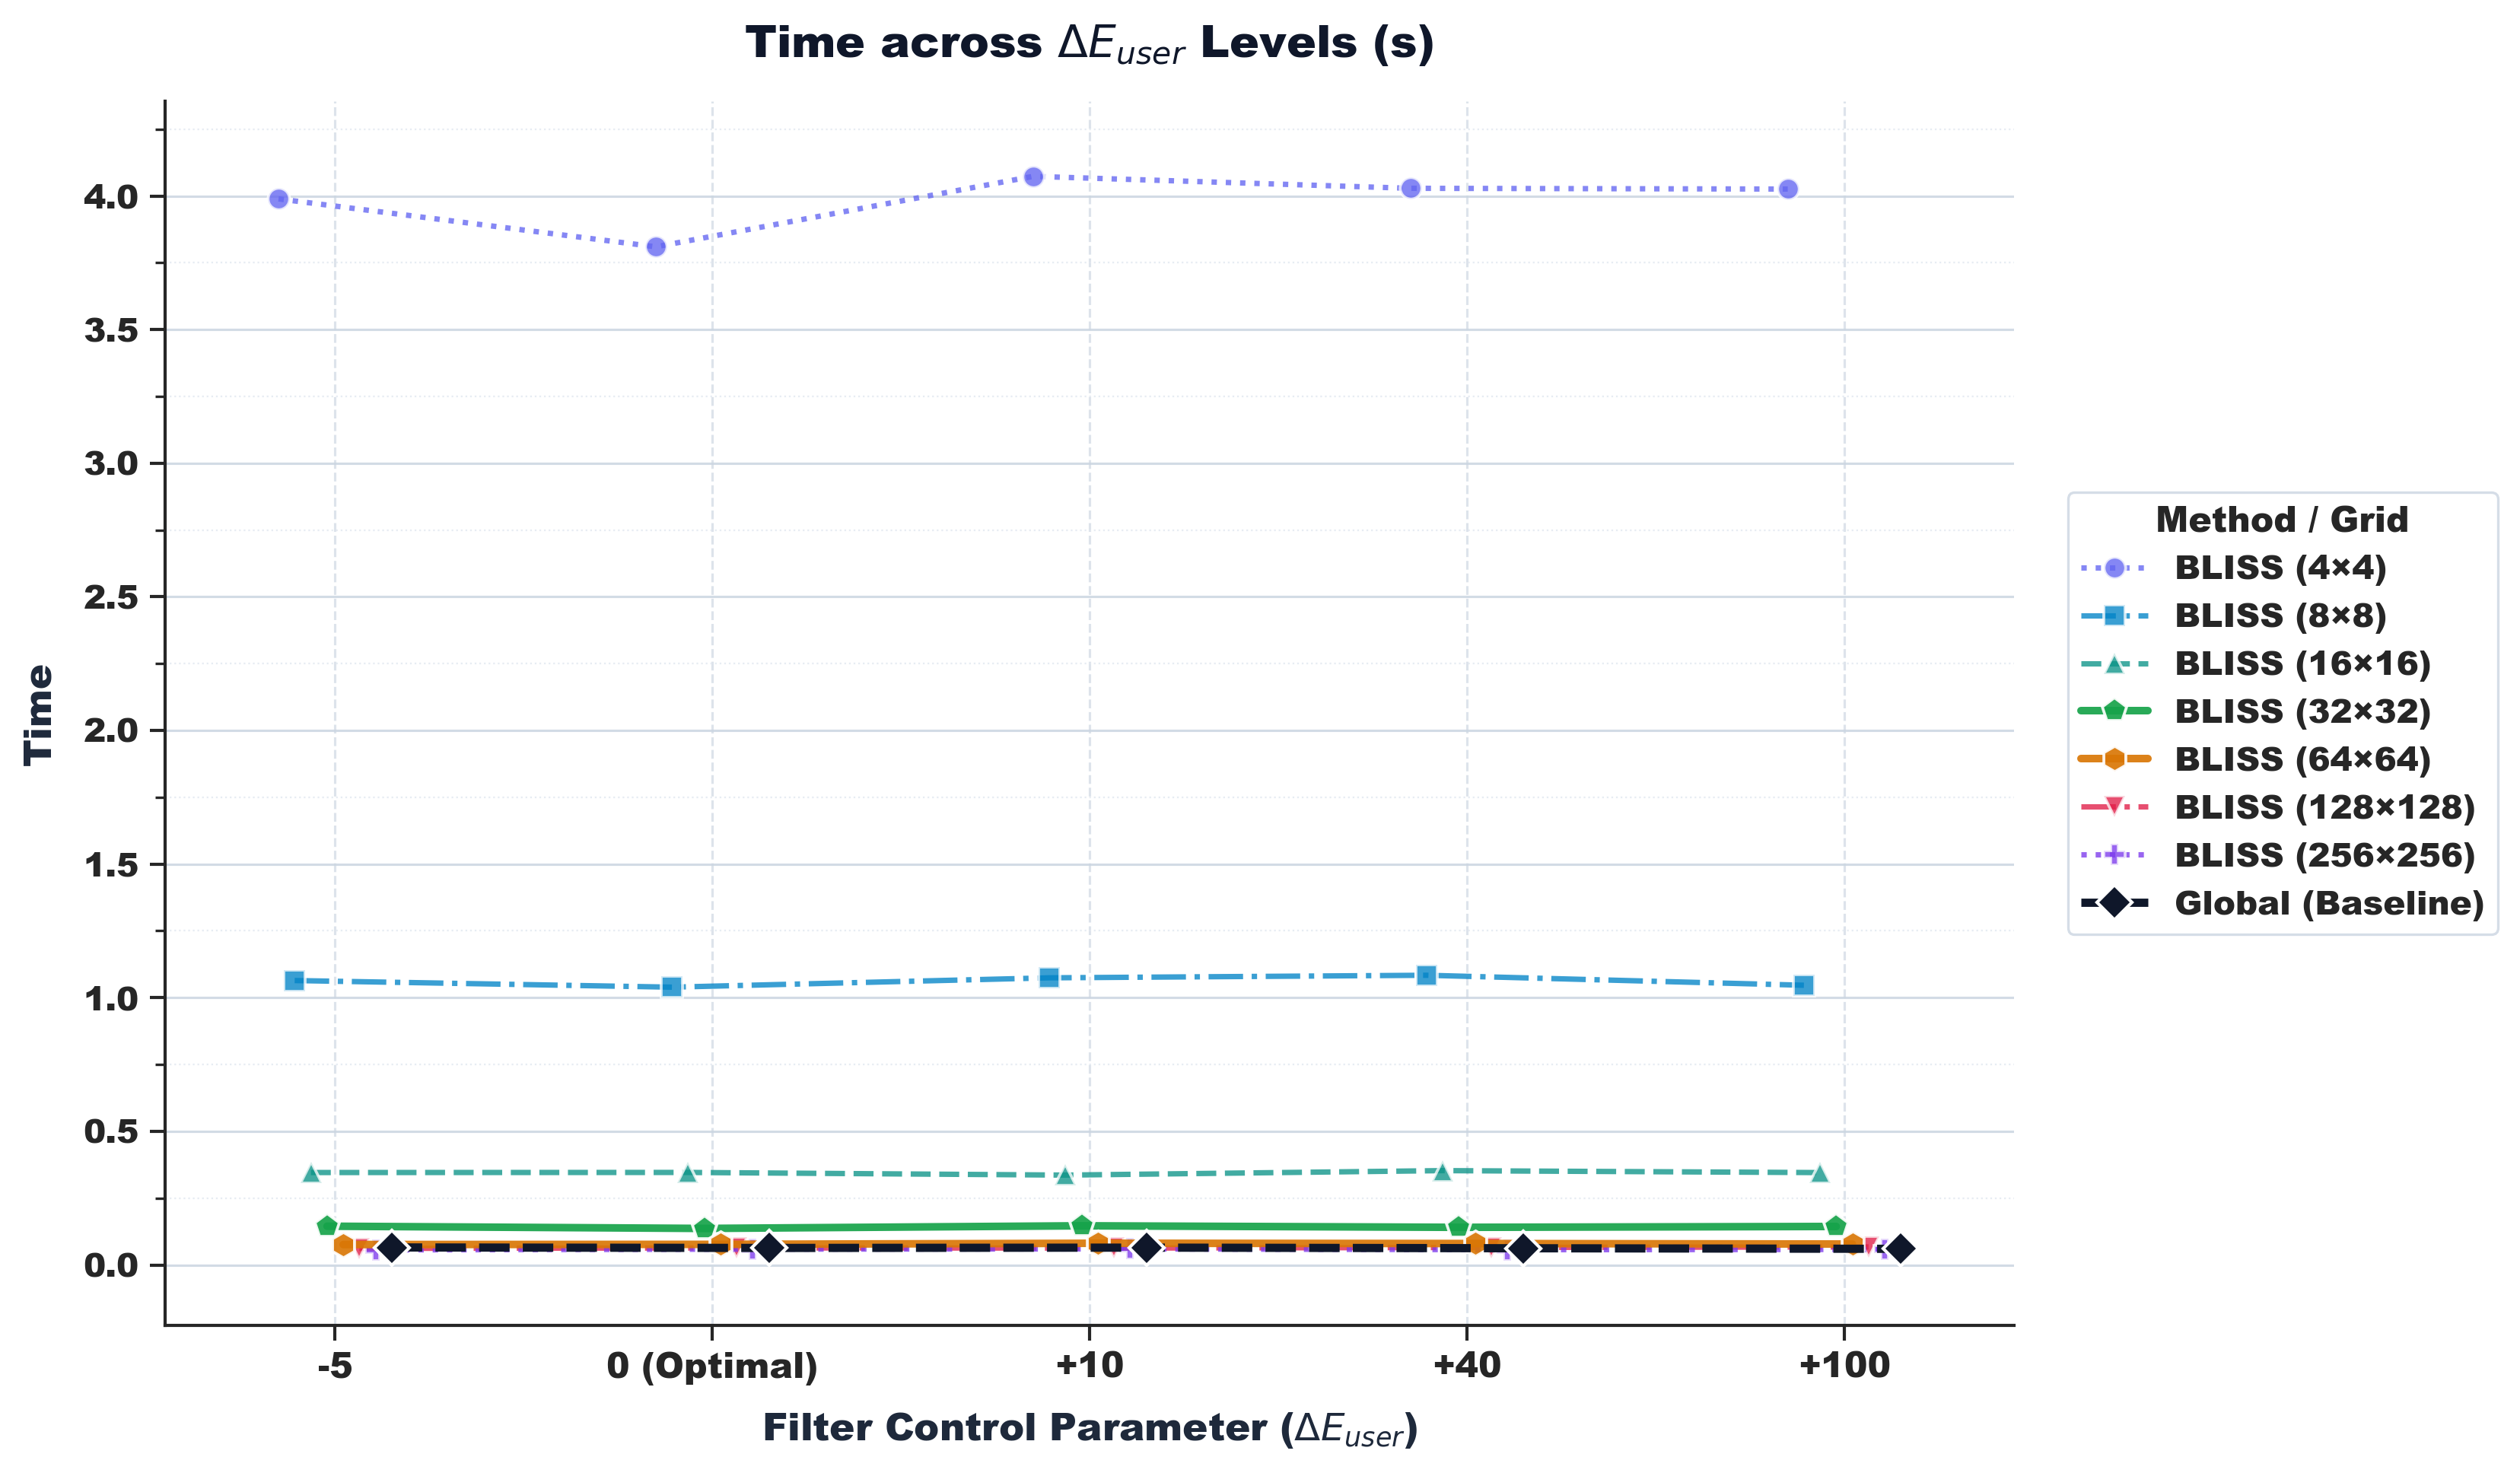

In [7]:
# Cell 5: Single-Panel Full-Range Metric Plots (-5 to +100) with High Visual Separation
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator, AutoMinorLocator, FixedLocator, ScalarFormatter
import seaborn as sns

ASSETS_DIR = os.path.join(PROJECT_ROOT, "assets")
PLOTS_DIR = os.path.join(ASSETS_DIR, "metric_curves")
os.makedirs(PLOTS_DIR, exist_ok=True)

plot_metrics = [
    "PSNR (Higher is Better)",
    "SSIM Overall (Higher is Better)",
    "GMSD (Lower is Better)",
    "Blue Absorption (Higher is Better)",
    "Volume Difference (Lower is Better)",
    "Delta E 2000 (Lower is Better)",
    "BRISQUE (Lower is Better)",
    "Time (s) (Lower is Better)",
]

# Keep only metrics present in df_results
plot_metrics = [m for m in plot_metrics if m in df_results.columns]

for opt_metric in ["NIQE (Lower is Better)", "PIQE (Lower is Better)"]:
    if opt_metric in df_results.columns and df_results[opt_metric].abs().sum() > 0:
        plot_metrics.insert(-1, opt_metric)

df_plot_agg = (
    df_results.groupby(["Method", "Block_Size", "Delta_E_User"], as_index=False)[plot_metrics]
    .mean()
)
df_plot_agg["Block_Size_Str"] = df_plot_agg["Block_Size"].astype(str).str.strip()

sorted_grids = sorted(
    [bs for bs in df_plot_agg["Block_Size_Str"].unique() if bs.isdigit()],
    key=int,
)
sorted_de = sorted(df_plot_agg["Delta_E_User"].unique())
x_positions = np.arange(len(sorted_de))
x_labels = [
    "0 (Optimal)" if de == 0 else (f"+{de}" if de > 0 else f"{de}")
    for de in sorted_de
]

# Distinct, high-contrast, non-glaring scientific styles per grid size
grid_styles = [
    {"color": "#6366f1", "marker": "o", "ls": ":"},    # 4x4   - Soft Indigo
    {"color": "#0284c7", "marker": "s", "ls": "-."},   # 8x8   - Ocean Blue
    {"color": "#0d9488", "marker": "^", "ls": "--"},   # 16x16 - Muted Teal
    {"color": "#16a34a", "marker": "p", "ls": "-"},    # 32x32 - Forest Sage
    {"color": "#d97706", "marker": "h", "ls": "-"},    # 64x64 - Warm Amber
    {"color": "#e11d48", "marker": "v", "ls": "-."},   # 128x128 - Muted Rose
    {"color": "#7c3aed", "marker": "P", "ls": ":"},    # 256x256 - Soft Violet
]

# Horizontal micro-dodging so markers sit side-by-side at each Delta E level
n_curves = len(sorted_grids) + 1
dodge_offsets = np.linspace(-0.15, 0.15, n_curves)

sns.set_theme(style="ticks", context="paper", font_scale=1.2)

for metric_col in plot_metrics:
    fig, ax = plt.subplots(figsize=(11.2, 6.6))

    clean_metric_title = metric_col.split("(")[0].strip()
    direction_hint = "(" + metric_col.split("(")[1] if "(" in metric_col else ""

    all_y_vals = []

    # 1. Plot each BLISS grid curve with unique color, marker, line style, and horizontal offset
    for idx, bs in enumerate(sorted_grids):
        sub_grid = (
            df_plot_agg[
                (df_plot_agg["Method"] == "BLISS (Local+Smoothness)")
                & (df_plot_agg["Block_Size_Str"] == bs)
            ]
            .sort_values("Delta_E_User")
        )
        if sub_grid.empty:
            continue

        st = grid_styles[idx % len(grid_styles)]
        is_key = bs in ("32", "64")
        y_vals = sub_grid[metric_col].values
        all_y_vals.extend(y_vals)

        ax.plot(
            x_positions + dodge_offsets[idx],
            y_vals,
            color=st["color"],
            marker=st["marker"],
            linestyle=st["ls"],
            markersize=8.0 if is_key else 6.8,
            markeredgecolor="white",
            markeredgewidth=0.9,
            linewidth=2.4 if is_key else 1.7,
            alpha=0.92 if is_key else 0.78,
            zorder=6 if is_key else 4,
            label=f"BLISS ({bs}×{bs})",
        )

    # 2. Plot Global (Paper Baseline) as a bold dark reference curve
    sub_global = (
        df_plot_agg[
            (df_plot_agg["Method"] == "Global (Paper)")
            & (df_plot_agg["Block_Size_Str"].isin(["Full", "None", "nan"]))
        ]
        .sort_values("Delta_E_User")
    )
    if not sub_global.empty:
        y_global = sub_global[metric_col].values
        all_y_vals.extend(y_global)

        ax.plot(
            x_positions + dodge_offsets[-1],
            y_global,
            color="#0f172a",
            marker="D",
            linestyle="--",
            markersize=7.8,
            markeredgecolor="white",
            markeredgewidth=1.0,
            linewidth=2.6,
            zorder=10,
            label="Global (Baseline)",
        )

    # 3. Smart Y-Axis Scaling: Expand dense regions without cropping [-5, +100]
    y_min, y_max = min(all_y_vals), max(all_y_vals)
    y_span = max(y_max - y_min, 1e-6)
    ylabel_text = clean_metric_title

    if "SSIM" in metric_col and y_max <= 1.0001 and (1.0 - y_min) > 3.5 * (1.0 - np.median(all_y_vals)):
        # Expand values clustered near 1.0 while keeping full range down to y_min
        ax.set_yscale(
            "function",
            functions=(
                lambda y: np.sign(y - 1.0) * np.power(np.abs(y - 1.0), 0.45),
                lambda z: 1.0 + np.sign(z) * np.power(np.abs(z), 1.0 / 0.45),
            ),
        )
        candidate_ticks = [0.2, 0.4, 0.5, 0.6, 0.7, 0.75, 0.8, 0.85, 0.9, 0.92, 0.94, 0.96, 0.97, 0.98, 0.985, 0.99, 0.995, 1.0]
        visible_ticks = [t for t in candidate_ticks if (y_min - 0.03 * y_span) <= t <= min(1.0, y_max + 0.02 * y_span)]
        if len(visible_ticks) >= 4:
            ax.yaxis.set_major_locator(FixedLocator(visible_ticks))
            ax.yaxis.set_major_formatter(ScalarFormatter())
        ylabel_text = f"{clean_metric_title} (Expanded Near 1.0)"

    elif "GMSD" in metric_col and y_min >= 0 and y_max > 4.0 * max(np.median(all_y_vals), 1e-6):
        # Expand small distortion values near 0.0 while keeping full range up to +100
        ax.set_yscale(
            "function",
            functions=(
                lambda y: np.sign(y) * np.power(np.abs(y), 0.45),
                lambda z: np.sign(z) * np.power(np.abs(z), 1.0 / 0.45),
            ),
        )
        candidate_ticks = [0.0, 0.001, 0.002, 0.003, 0.005, 0.008, 0.012, 0.02, 0.03, 0.05, 0.08, 0.12]
        visible_ticks = [t for t in candidate_ticks if max(0.0, y_min - 0.02 * y_span) <= t <= (y_max + 0.05 * y_span)]
        if len(visible_ticks) >= 4:
            ax.yaxis.set_major_locator(FixedLocator(visible_ticks))
            ax.yaxis.set_major_formatter(ScalarFormatter())
        ylabel_text = f"{clean_metric_title} (Expanded Near 0.0)"

    else:
        # Tight linear scale with 11 major ticks and minor subdivisions for accurate reading
        pad = y_span * 0.07
        ax.set_ylim(y_min - pad, y_max + pad)
        ax.yaxis.set_major_locator(MaxNLocator(nbins=11))
        ax.yaxis.set_minor_locator(AutoMinorLocator(2))

    # 4. Clean Academic Axes, Gridlines, and External Legend (No colored zones, no text clutter)
    ax.set_title(
        rf"{clean_metric_title} across $\Delta E_{{user}}$ Levels {direction_hint}",
        fontsize=14,
        fontweight="bold",
        color="#0f172a",
        pad=14,
    )
    ax.set_xlabel(r"Filter Control Parameter ($\Delta E_{user}$)", fontsize=12, fontweight="bold", color="#1e293b", labelpad=8)
    ax.set_ylabel(ylabel_text, fontsize=12, fontweight="bold", color="#1e293b", labelpad=8)

    ax.set_xticks(x_positions)
    ax.set_xticklabels(x_labels, fontsize=11)
    ax.set_xlim(-0.45, len(sorted_de) - 0.55)

    # Fine major and minor gridlines so every curve's Y-value can be read off accurately
    ax.grid(True, which="major", axis="y", linestyle="-", linewidth=0.75, color="#cbd5e1", alpha=0.85)
    ax.grid(True, which="minor", axis="y", linestyle=":", linewidth=0.55, color="#e2e8f0", alpha=0.8)
    ax.grid(True, which="major", axis="x", linestyle="--", linewidth=0.75, color="#cbd5e1", alpha=0.65)
    sns.despine(ax=ax, top=True, right=True)

    ax.legend(
        title="Method / Grid",
        title_fontsize=11,
        fontsize=10.5,
        frameon=True,
        facecolor="#ffffff",
        edgecolor="#cbd5e1",
        loc="center left",
        bbox_to_anchor=(1.02, 0.5),
    )

    plt.tight_layout()
    safe_name = clean_metric_title.lower().replace(" ", "_")
    save_file = os.path.join(PLOTS_DIR, f"curve_{safe_name}.png")
    plt.savefig(save_file, dpi=300, bbox_inches="tight")
    plt.show()

# print(f"All {len(plot_metrics)} full-range metric plots saved to: {PLOTS_DIR}")